In [213]:
import numpy as np
import re
import random
import matplotlib.pyplot as plt
import math
from collections import Counter, defaultdict
from datasets import load_dataset

In [214]:
dataset = load_dataset(
    "parquet",
    data_files={
        "train": "https://huggingface.co/datasets/eriktks/conll2000/resolve/f7bc5ce921058824d5a9843f6a9b6a319e0ac11b/data/train-00000-of-00001.parquet",
        "test": "https://huggingface.co/datasets/eriktks/conll2000/resolve/f7bc5ce921058824d5a9843f6a9b6a319e0ac11b/data/test-00000-of-00001.parquet"
    }
)

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags'],
        num_rows: 8937
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags'],
        num_rows: 2013
    })
})


In [215]:
all_train_data = dataset["train"]

np.random.seed(50) # to have the same random split everytime 

indices = np.random.permutation(len(all_train_data)) #Creates a randomly shuffled sequence of indices

split_point = int(0.8 * len(indices)) 
#80% for training and 20% for validation.
train_indices = indices[:split_point]
validation_indices = indices[split_point:]

train_data = all_train_data.select(train_indices)
validation_data = all_train_data.select(validation_indices)

test_data = dataset["test"]

print("Training sentences:", len(train_data))
print("Validation sentences:", len(validation_data))
print("Testing sentences:", len(test_data))

Training sentences: 7149
Validation sentences: 1788
Testing sentences: 2013


Preprocessing of the data 

In [216]:
import string

def preprocess_sentence(sentence):
    return [
        token.strip()   # only remove whitespace; keep capitalisation, punctuation and every token
        for token in sentence
        if token.strip()
    ]

#preprocess all for consistent format
train_sentences = [
    preprocess_sentence(s)
    for s in train_data["tokens"]
]

validation_sentences = [
    preprocess_sentence(s)
    for s in validation_data["tokens"]
]

test_sentences = [
    preprocess_sentence(s)
    for s in test_data["tokens"]
]

print("Original sentence:", train_data["tokens"][0])
print("Processed sentence:", train_sentences[0])


Original sentence: ['Congress', 'has', 'enough', 'difficulty', 'dealing', 'with', 'the', 'realities', 'of', 'the', 'world', 'as', 'it', 'currently', 'exists', '.']
Processed sentence: ['Congress', 'has', 'enough', 'difficulty', 'dealing', 'with', 'the', 'realities', 'of', 'the', 'world', 'as', 'it', 'currently', 'exists', '.']


Building the vocabulary

Identify all the unique words that appear in the training data and count how often each word appears.

In [217]:
word_counts = Counter() # count of unique words in the training set

for sentence in train_sentences:

    for word in sentence:

        word_counts[word] += 1

print("Total unique words:", len(word_counts))
print(word_counts.most_common(10)) #returns the ten most frequent words and their counts

Total unique words: 16992
[(',', 8599), ('the', 7326), ('.', 6988), ('of', 4148), ('to', 4010), ('a', 3433), ('and', 2882), ('in', 2705), ("'s", 1535), ('for', 1495)]


The minimum number of times a word must appear to be included

In [218]:

for min_count in [1, 2, 4, 10, 20]:
    vocabulary = []

    for word in word_counts:
        if word_counts[word] >= min_count:
            vocabulary.append(word)

    print("Minimum count:", min_count)
    print("Vocabulary size:", len(vocabulary))
    print("----------------------")

Minimum count: 1
Vocabulary size: 16992
----------------------
Minimum count: 2
Vocabulary size: 8456
----------------------
Minimum count: 4
Vocabulary size: 4535
----------------------
Minimum count: 10
Vocabulary size: 2017
----------------------
Minimum count: 20
Vocabulary size: 1042
----------------------


In [219]:
min_count = 2

vocabulary = []

for word in word_counts:
    #word must occur at least twice in the training sentences to be included
    if word_counts[word] >= min_count:
        vocabulary.append(word)

word_to_id = {} # mapping from word to unique integer ID

for i in range(len(vocabulary)):
    word_to_id[vocabulary[i]] = i

id_to_word = {} # mapping from unique integer ID to word

for word in word_to_id:
    id_to_word[word_to_id[word]] = word

print("Final vocabulary size:", len(vocabulary))

Final vocabulary size: 8456


Measuring unknown words 
Words present in the validation and tetsing but not in the training data


In [220]:
unknown_validation = 0
total_validation = 0

for sentence in validation_sentences:
    for word in sentence:
        total_validation += 1 #counts every token in the validation set
        #checks whether the word has a corresponding vocabulary ID.
        if word not in word_to_id:
            unknown_validation += 1

unknown_test = 0
total_test = 0

for sentence in test_sentences:
    for word in sentence:
        total_test += 1 #counts every token in the test set

        if word not in word_to_id:
            unknown_test += 1

print("Unknown validation words:", unknown_validation)
print("Validation unknown percentage:", 100 * unknown_validation / total_validation)

print("Unknown test words:", unknown_test)
print("Test unknown percentage:", 100 * unknown_test / total_test)

Unknown validation words: 3562
Validation unknown percentage: 8.370934386162812
Unknown test words: 5063
Test unknown percentage: 10.686620089917048


PPMI — Positive Pointwise Mutual Information
PPMI tries to understand a word through its surrounding words
PPMI measures how strongly a word is associated with a context word


In [221]:
def build_cooccurrence(sentences, window_size):

    cooccurrence = {} #to store word-pair counts

    for sentence in sentences: # through every sentence

        for i in range(len(sentence)): # through everyword in the sentence 

            center_word = sentence[i]
            #If the center word is not in  vocabulary
            if center_word not in word_to_id:
                continue # skip it

            if center_word not in cooccurrence:
                cooccurrence[center_word] = {}
            # setting the boundaries for the context window
            start = max(0, i - window_size)
            end = min(len(sentence), i + window_size + 1)

            for j in range(start, end):

                if i == j: # center wod itself
                    continue

                context_word = sentence[j]

                if context_word not in word_to_id: #skip it if it is not in the vocabulary
                    continue
                #context word not recorded before
                if context_word not in cooccurrence[center_word]:
                    # add it and intialize it 
                    cooccurrence[center_word][context_word] = 0 

                cooccurrence[center_word][context_word] += 1

    return cooccurrence

In [222]:
for window in [1, 2, 3, 4]:

    cooccurrence = build_cooccurrence(train_sentences, window)

    number_of_pairs = 0

    for word in cooccurrence:
        number_of_pairs += len(cooccurrence[word])

    print("Window size:", window)
    print("Different word pairs:", number_of_pairs)
    print("----------------------")

Window size: 1
Different word pairs: 138440
----------------------
Window size: 2
Different word pairs: 265390
----------------------
Window size: 3
Different word pairs: 377353
----------------------
Window size: 4
Different word pairs: 476028
----------------------


Converting Counts to Scores

In [223]:
def calculate_ppmi(cooccurrence):

    total = 0 # total number of word-context pairs
    #Count(context word,*)
    word_counts_pmi = {} #total context occurrences for each center word
    context_counts = {}  #How many times each word appears as a context word

    for word in cooccurrence:

        word_counts_pmi[word] = 0
        #through all context words associated with the current center word
        for context in cooccurrence[word]:
            # count how many times ther appeared together
            count = cooccurrence[word][context] 

            total += count
            word_counts_pmi[word] += count
            # First time encountering this context word
            if context not in context_counts:
                context_counts[context] = 0
            #Count(*,contextword) 
            context_counts[context] += count

    ppmi = {}

    for word in cooccurrence:

        ppmi[word] = {}

        for context in cooccurrence[word]:

            count = cooccurrence[word][context]

            pmi = math.log(
                (count * total) /
                (word_counts_pmi[word] * context_counts[context])
            )

            if pmi > 0:
                # Stores the positive PMI value in the PPMI dictionary.
                ppmi[word][context] = pmi 

    return ppmi

Testing different window sizes

Window size: 1
Different word pairs: 138440
PPMI words: 8456
----------------------
Window size: 2
Different word pairs: 265390
PPMI words: 8456
----------------------
Window size: 3
Different word pairs: 377353
PPMI words: 8456
----------------------
Window size: 4
Different word pairs: 476028
PPMI words: 8456
----------------------


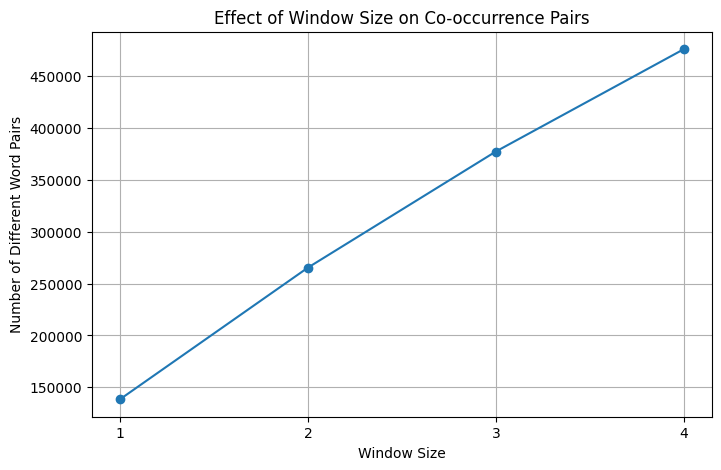

All PPMI representations have been created successfully!


In [224]:
# Build and store PPMI representations for different window sizes

window_sizes = [1, 2, 3, 4]

ppmi_results = {}
cooccurrence_pair_counts = []

for window in window_sizes:

    # Build the co-occurrence matrix
    cooccurrence = build_cooccurrence(train_sentences, window)

    # Convert co-occurrence counts into PPMI vectors
    ppmi_vectors = calculate_ppmi(cooccurrence)

    # Store the PPMI representation for this window size
    ppmi_results[window] = ppmi_vectors

    # Count different word-context pairs
    number_of_pairs = sum(
        len(contexts)
        for contexts in cooccurrence.values()
    )

    cooccurrence_pair_counts.append(number_of_pairs)

    print("Window size:", window)
    print("Different word pairs:", number_of_pairs)
    print("PPMI words:", len(ppmi_vectors))
    print("----------------------")


# Visualize the number of different co-occurrence pairs

plt.figure(figsize=(8, 5))

plt.plot(
    window_sizes,
    cooccurrence_pair_counts,
    marker="o"
)

plt.xlabel("Window Size")
plt.ylabel("Number of Different Word Pairs")
plt.title("Effect of Window Size on Co-occurrence Pairs")
plt.xticks(window_sizes)
plt.grid(True)
plt.show()

print("All PPMI representations have been created successfully!")

In [225]:
print("PPMI exists:", "ppmi_results" in globals())

if "ppmi_results" in globals():
    print("Available windows:", ppmi_results.keys())

PPMI exists: True
Available windows: dict_keys([1, 2, 3, 4])


Comparing PPMI vectors using cosine similarity

In [226]:
def sparse_cosine(vector1, vector2):

    dot = 0

    for word in vector1:

        if word in vector2:
            dot += vector1[word] * vector2[word]

    norm1 = 0
    norm2 = 0

    for value in vector1.values():
        norm1 += value ** 2

    for value in vector2.values():
        norm2 += value ** 2

    norm1 = math.sqrt(norm1)
    norm2 = math.sqrt(norm2)

    if norm1 == 0 or norm2 == 0:
        return 0

    return dot / (norm1 * norm2)

Finding the nearest neighbors

In [227]:
def find_sparse_neighbors(query_word, vectors, number=5):

    if query_word not in vectors:
        return []

    similarities = []

    for word in vectors:

        if word == query_word:
            continue

        similarity = sparse_cosine(
            vectors[query_word],
            vectors[word]
        )

        similarities.append((word, similarity))

    similarities.sort(key=lambda x: x[1], reverse=True)

    return similarities[:number]

TF-IDF — Term Frequency–Inverse Document Frequency

TF-IDF is commonly used in information retrieval and document analysis
- A word is important to a document if it appears frequently in that document
- But a word is less informative if it appears in almost every document

In [228]:
#times each word appears in each sentence
term_frequency = {}
# number of different sentences contain each word
document_frequency = {}
# number of training sentences
number_of_documents = len(train_sentences) 

for i in range(number_of_documents):

    sentence = train_sentences[i]

    word_counts_in_document = Counter(sentence) #counts the occurrences of each word in that sentence

    for word in word_counts_in_document:

        if word not in word_to_id:
            continue

        if word not in term_frequency:
            term_frequency[word] = {}
        #store the number of times the word appeared in sentence i
        term_frequency[word][i] = word_counts_in_document[word]

        if word not in document_frequency:
            document_frequency[word] = 0
        #increment the number of documents containing the word
        document_frequency[word] += 1
#Number of times a word appears in a document
print("Words with TF:", len(term_frequency))

Words with TF: 8456


In [229]:
idf_results = {}

for formula in [1, 2, 3]:

    idf_results[formula] = {}

    for word in document_frequency:

        df = document_frequency[word]
        # Smoothed IDF with an added 1
        if formula == 1:
            idf = math.log((number_of_documents + 1) / (df + 1)) + 1

        elif formula == 2:
            idf = math.log((number_of_documents + 1) / (df + 1))

        else:
            idf = math.log(number_of_documents / df)

        idf_results[formula][word] = idf

    print("IDF formula:", formula)
    print("Example IDF:", list(idf_results[formula].items())[:5])
    print("----------------------")

IDF formula: 1
Example IDF: [('Congress', 5.685212893661628), ('has', 3.6365430106485457), ('enough', 6.161295568983745), ('difficulty', 7.92895748663274), ('dealing', 8.265429723253952)]
----------------------
IDF formula: 2
Example IDF: [('Congress', 4.685212893661628), ('has', 2.6365430106485457), ('enough', 5.161295568983745), ('difficulty', 6.92895748663274), ('dealing', 7.265429723253953)]
----------------------
IDF formula: 3
Example IDF: [('Congress', 4.700340495871215), ('has', 2.6383581755631473), ('enough', 5.185848311652915), ('difficulty', 7.082968296538797), ('dealing', 7.488433404646961)]
----------------------


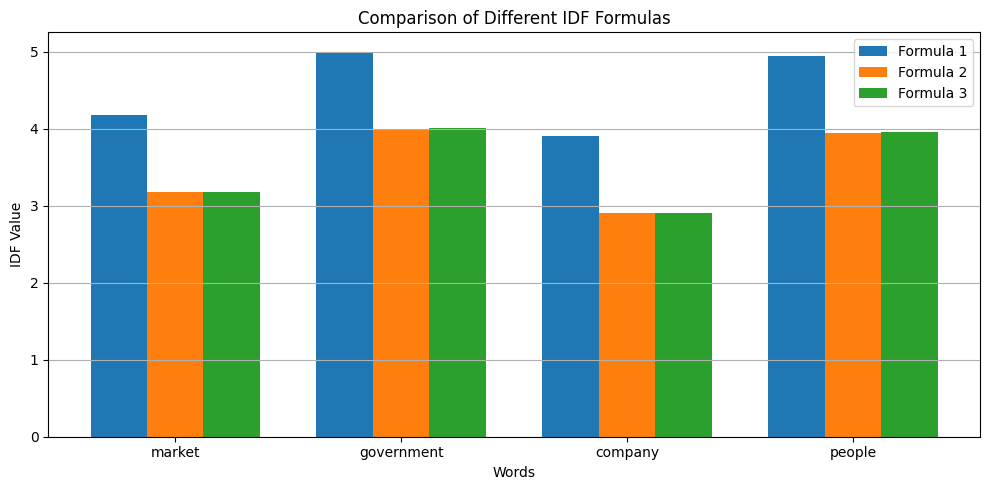

In [230]:

# Compare IDF values for selected words

selected_words = [
    "market",
    "government",
    "company",
    "people"
]

# Keep only words that exist in all three IDF dictionaries
selected_words = [
    word for word in selected_words
    if all(word in idf_results[formula] for formula in [1, 2, 3])
]

formula_1_values = [
    idf_results[1][word] for word in selected_words
]

formula_2_values = [
    idf_results[2][word] for word in selected_words
]

formula_3_values = [
    idf_results[3][word] for word in selected_words
]

x = np.arange(len(selected_words))
width = 0.25

plt.figure(figsize=(10, 5))

plt.bar(
    x - width,
    formula_1_values,
    width,
    label="Formula 1"
)

plt.bar(
    x,
    formula_2_values,
    width,
    label="Formula 2"
)

plt.bar(
    x + width,
    formula_3_values,
    width,
    label="Formula 3"
)

plt.xlabel("Words")
plt.ylabel("IDF Value")
plt.title("Comparison of Different IDF Formulas")
plt.xticks(x, selected_words)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()


Building TF-IDF word vectors

In [231]:
idf = idf_results[1]

tfidf_vectors = {}

for word in term_frequency:

    tfidf_vectors[word] = {}

    for document in term_frequency[word]:

        tf = term_frequency[word][document]

        tfidf = tf * idf[word]

        tfidf_vectors[word][document] = tfidf

print("Number of TF-IDF word vectors:", len(tfidf_vectors))

Number of TF-IDF word vectors: 8456


Comparing IDF formulas

In [232]:
for formula in [1, 2, 3]:

    current_vectors = {}

    for word in term_frequency:

        current_vectors[word] = {}

        for document in term_frequency[word]:

            tf = term_frequency[word][document]

            current_vectors[word][document] = tf * idf_results[formula][word]

    print("IDF formula:", formula)

    print(
        find_sparse_neighbors(
            "market",
            current_vectors
        )
    )

    print("----------------------")

IDF formula: 1
[('the', 0.2227567598347044), ('stock', 0.20193066160058581), ('.', 0.19608932788280517), (',', 0.16024772787388986), ('investors', 0.14592409074363794)]
----------------------
IDF formula: 2
[('the', 0.22275675983469417), ('stock', 0.20193066160058612), ('.', 0.19608932788277758), (',', 0.1602477278738861), ('investors', 0.14592409074363788)]
----------------------
IDF formula: 3
[('the', 0.22275675983470145), ('stock', 0.2019306616005858), ('.', 0.19608932788279826), (',', 0.1602477278738883), ('investors', 0.14592409074363777)]
----------------------


Word2Vec — Skip-Gram with Negative Sampling (SGNS)
Word2Vec learns word vectors through training


In [233]:
# Convert training sentences into IDs
train_ids = [
    [word_to_id.get(word, None) for word in sentence]
    for sentence in train_sentences
]

# Convert validation sentences into IDs
validation_ids = [
    [word_to_id.get(word, None) for word in sentence]
    for sentence in validation_sentences
]

print("Training sentences:", len(train_ids))
print("Validation sentences:", len(validation_ids))

# Check an example
print("Original sentence:", train_sentences[0])
print("ID sentence:", train_ids[0])

Training sentences: 7149
Validation sentences: 1788
Original sentence: ['Congress', 'has', 'enough', 'difficulty', 'dealing', 'with', 'the', 'realities', 'of', 'the', 'world', 'as', 'it', 'currently', 'exists', '.']
ID sentence: [0, 1, 2, 3, 4, 5, 6, 7, 8, 6, 9, 10, 11, 12, 13, 14]


In [234]:
def generate_pairs(sentences, window_size):

    pairs = []

    for sentence in sentences:

        for i, center_word in enumerate(sentence):

            if center_word is None:
                continue

            start = max(0, i - window_size)
            end = min(len(sentence), i + window_size + 1)

            for j in range(start, end):

                if i == j:
                    continue

                context_word = sentence[j]

                # Skip unknown context words
                if context_word is None:
                    continue

                pairs.append((center_word, context_word))

    return pairs

In [235]:
for window in [1, 2, 3]:

    pairs = generate_pairs(train_ids, window)

    print("Window size:", window)
    print("Number of training pairs:", len(pairs))
    print("----------------------")

Window size: 1
Number of training pairs: 292320
----------------------
Window size: 2
Number of training pairs: 572244
----------------------
Window size: 3
Number of training pairs: 839652
----------------------


In [236]:
vocab_size = len(vocabulary)

embedding_dim = 50
negative_samples = 5
learning_rate = 0.025
epochs = 10
window_size = 2

print("Vocabulary size:", vocab_size)
print("Embedding dimension:", embedding_dim)
print("Negative samples:", negative_samples)
print("Learning rate:", learning_rate)
print("Epochs:", epochs)

Vocabulary size: 8456
Embedding dimension: 50
Negative samples: 5
Learning rate: 0.025
Epochs: 10


In [237]:
np.random.seed(42)
random.seed(42)

input_embeddings = np.random.uniform(
    -0.5 / embedding_dim,
    0.5 / embedding_dim,
    (vocab_size, embedding_dim)
)

output_embeddings = np.zeros(
    (vocab_size, embedding_dim)
)

print("Input embeddings:", input_embeddings.shape)
print("Output embeddings:", output_embeddings.shape)

Input embeddings: (8456, 50)
Output embeddings: (8456, 50)


In [238]:
word_frequencies = np.zeros(vocab_size)

for word, word_id in word_to_id.items():

    word_frequencies[word_id] = word_counts[word]

negative_distribution = word_frequencies ** 0.75

negative_distribution /= negative_distribution.sum()

print("Negative distribution sum:", negative_distribution.sum())

Negative distribution sum: 1.0


In [239]:
def sigmoid(x):

    x = np.clip(x, -15, 15)

    return 1 / (1 + np.exp(-x))

In [240]:
def train_pair(
    center_id,
    context_id,
    input_embeddings,
    output_embeddings,
    negative_distribution,
    negative_samples,
    learning_rate,
    rng
):

    # Get center embedding
    center_vector = input_embeddings[center_id].copy()

    # Get positive context embedding
    positive_vector = output_embeddings[context_id].copy()

    # --------------------------------
    # 1. Positive forward computation
    # --------------------------------

    positive_score = np.dot(center_vector, positive_vector)

    positive_probability = sigmoid(positive_score)

    positive_loss = np.logaddexp(0, -positive_score)

    # --------------------------------
    # 2. Positive gradients
    # --------------------------------
    positive_gradient = positive_probability - 1

    center_gradient = positive_gradient * positive_vector

    positive_output_gradient = positive_gradient * center_vector

    # --------------------------------
    # 3. Negative sampling
    # --------------------------------

    negative_ids = []

    while len(negative_ids) < negative_samples:

        negative_id = rng.choice(
            len(negative_distribution),
            p=negative_distribution
        )

        # Exclude the actual positive context
        if negative_id != context_id:
            negative_ids.append(negative_id)

    negative_loss = 0

    negative_output_gradients = {}

    # --------------------------------
    # 4. Negative forward computation
    # --------------------------------

    for negative_id in negative_ids:

        negative_vector = output_embeddings[negative_id].copy()

        negative_score = np.dot(center_vector, negative_vector)

        negative_probability = sigmoid(negative_score)

        negative_loss += np.logaddexp(0, negative_score)

        # --------------------------------
        # 5. Negative gradients
        # --------------------------------

        negative_gradient = negative_probability

        center_gradient += negative_gradient * negative_vector

        if negative_id not in negative_output_gradients:
            negative_output_gradients[negative_id] = np.zeros_like(center_vector)

        negative_output_gradients[negative_id] += (
            negative_gradient * center_vector
        )

    # --------------------------------
    # 6. Update input embedding
    # --------------------------------

    input_embeddings[center_id] -= (
        learning_rate * center_gradient
    )
    # --------------------------------
    # 7. Update positive output embedding
    # --------------------------------

    output_embeddings[context_id] -= (
        learning_rate * positive_output_gradient
    )

    # --------------------------------
    # 8. Update negative output embeddings
    # --------------------------------

    for negative_id, gradient in negative_output_gradients.items():

        output_embeddings[negative_id] -= (
            learning_rate * gradient
        )

    return positive_loss + negative_loss
training_pairs = generate_pairs(train_ids, window_size)

validation_pairs = generate_pairs(validation_ids, window_size)

print("Training pairs:", len(training_pairs))
print("Validation pairs:", len(validation_pairs))

Training pairs: 572244
Validation pairs: 134118


generate the negative samples once and reuse them for every epoch and experiment.

In [241]:
def generate_validation_negatives(
    pairs,
    negative_distribution,
    negative_samples,
    seed=42
):

    rng = np.random.default_rng(seed)

    validation_negatives = np.zeros(
        (len(pairs), negative_samples),
        dtype=int
    )

    for i, (center_id, context_id) in enumerate(pairs):

        negatives = []

        while len(negatives) < negative_samples:

            negative_id = rng.choice(
                len(negative_distribution),
                p=negative_distribution
            )

            if negative_id != context_id:
                negatives.append(negative_id)

        validation_negatives[i] = negatives

    return validation_negatives

In [242]:
def calculate_validation_loss(
    pairs,
    validation_negatives,
    input_embeddings,
    output_embeddings
):

    total_loss = 0

    for i, (center_id, context_id) in enumerate(pairs):

        center_vector = input_embeddings[center_id]

        # Positive score
        positive_vector = output_embeddings[context_id]

        positive_score = np.dot(
            center_vector,
            positive_vector
        )

        loss = np.logaddexp(0, -positive_score)

        # Negative scores
        for negative_id in validation_negatives[i]:

            negative_vector = output_embeddings[negative_id]

            negative_score = np.dot(
                center_vector,
                negative_vector
            )

            loss += np.logaddexp(0, negative_score)

        total_loss += loss

    if len(pairs) == 0:
        return 0

    return total_loss / len(pairs)

In [243]:
def train_epoch(
    training_pairs,
    input_embeddings,
    output_embeddings,
    negative_distribution,
    negative_samples,
    learning_rate,
    rng
):

    shuffled_indices = rng.permutation(len(training_pairs))

    total_loss = 0

    for index in shuffled_indices:

        center_id, context_id = training_pairs[index]

        loss = train_pair(
            center_id,
            context_id,
            input_embeddings,
            output_embeddings,
            negative_distribution,
            negative_samples,
            learning_rate,
            rng
        )

        total_loss += loss

    return total_loss / len(training_pairs)

In [244]:
experiments = [
    [1, 50, 0.025],
    [2, 50, 0.025],
    [3, 50, 0.025],
    [2, 100, 0.025],
    [2, 100, 0.01],
    [3, 100, 0.025]
]

results = []

tuning_negative_samples = 5
tuning_epochs = 3

max_training_pairs = 20000
max_validation_pairs = 5000

for experiment_number, experiment in enumerate(experiments):

    window, dimension, rate = experiment

    print("Testing:", experiment)

    # Generate pairs for this window size
    current_training_pairs = generate_pairs(
        train_ids,
        window
    )

    current_validation_pairs = generate_pairs(
        validation_ids,
        window
    )

    # Use reproducible subsets for tuning
    tuning_rng = np.random.default_rng(100 + experiment_number)

    if len(current_training_pairs) > max_training_pairs:

        indices = tuning_rng.choice(
            len(current_training_pairs),
            max_training_pairs,
            replace=False
        )

        current_training_pairs = [
            current_training_pairs[i] for i in indices
        ]

    if len(current_validation_pairs) > max_validation_pairs:

        indices = tuning_rng.choice(
            len(current_validation_pairs),
            max_validation_pairs,
            replace=False
        )

        current_validation_pairs = [
            current_validation_pairs[i] for i in indices
        ]

    # Fixed validation negatives
    current_validation_negatives = generate_validation_negatives(
        current_validation_pairs,
        negative_distribution,
        tuning_negative_samples,
        seed=42
    )

    # Initialize fresh embeddings for every experiment
    current_input = np.random.default_rng(42).uniform(
        -0.5 / dimension,
        0.5 / dimension,
        (vocab_size, dimension)
    )

    current_output = np.zeros(
        (vocab_size, dimension)
    )

    rng = np.random.default_rng(1000 + experiment_number)

    # Train
    for epoch in range(tuning_epochs):

        train_loss = train_epoch(
            current_training_pairs,
            current_input,
            current_output,
            negative_distribution,
            tuning_negative_samples,
            rate,
            rng
        )

    # Evaluate
    validation_loss = calculate_validation_loss(
        current_validation_pairs,
        current_validation_negatives,
        current_input,
        current_output
    )

    results.append({
        "window": window,
        "dimension": dimension,
        "negative_samples": tuning_negative_samples,
        "learning_rate": rate,
        "validation_loss": validation_loss
    })

    print("Validation loss:", validation_loss)
    print("----------------------")

Testing: [1, 50, 0.025]
Validation loss: 3.8307695352575823
----------------------
Testing: [2, 50, 0.025]
Validation loss: 3.881618247417319
----------------------
Testing: [3, 50, 0.025]
Validation loss: 3.9015620088131495
----------------------
Testing: [2, 100, 0.025]
Validation loss: 3.8910976145129554
----------------------
Testing: [2, 100, 0.01]
Validation loss: 4.1565314916501075
----------------------
Testing: [3, 100, 0.025]
Validation loss: 3.935507829051372
----------------------


In [245]:
results.sort(key=lambda x: x["validation_loss"])

print("Hyperparameter results:\n")

for result in results:

    print(
        "Window:", result["window"],
        "| Dimension:", result["dimension"],
        "| Negative samples:", result["negative_samples"],
        "| Learning rate:", result["learning_rate"],
        "| Validation loss:", round(result["validation_loss"], 4)
    )

best_result = results[0]

print("\nBest configuration:")
print(best_result)

Hyperparameter results:

Window: 1 | Dimension: 50 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.8308
Window: 2 | Dimension: 50 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.8816
Window: 2 | Dimension: 100 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.8911
Window: 3 | Dimension: 50 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.9016
Window: 3 | Dimension: 100 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.9355
Window: 2 | Dimension: 100 | Negative samples: 5 | Learning rate: 0.01 | Validation loss: 4.1565

Best configuration:
{'window': 1, 'dimension': 50, 'negative_samples': 5, 'learning_rate': 0.025, 'validation_loss': np.float64(3.8307695352575823)}


In [246]:
window_size = best_result["window"]
embedding_dim = best_result["dimension"]
negative_samples = best_result["negative_samples"]
learning_rate = best_result["learning_rate"]

print("Selected window:", window_size)
print("Selected dimension:", embedding_dim)
print("Selected negative samples:", negative_samples)
print("Selected learning rate:", learning_rate)

Selected window: 1
Selected dimension: 50
Selected negative samples: 5
Selected learning rate: 0.025


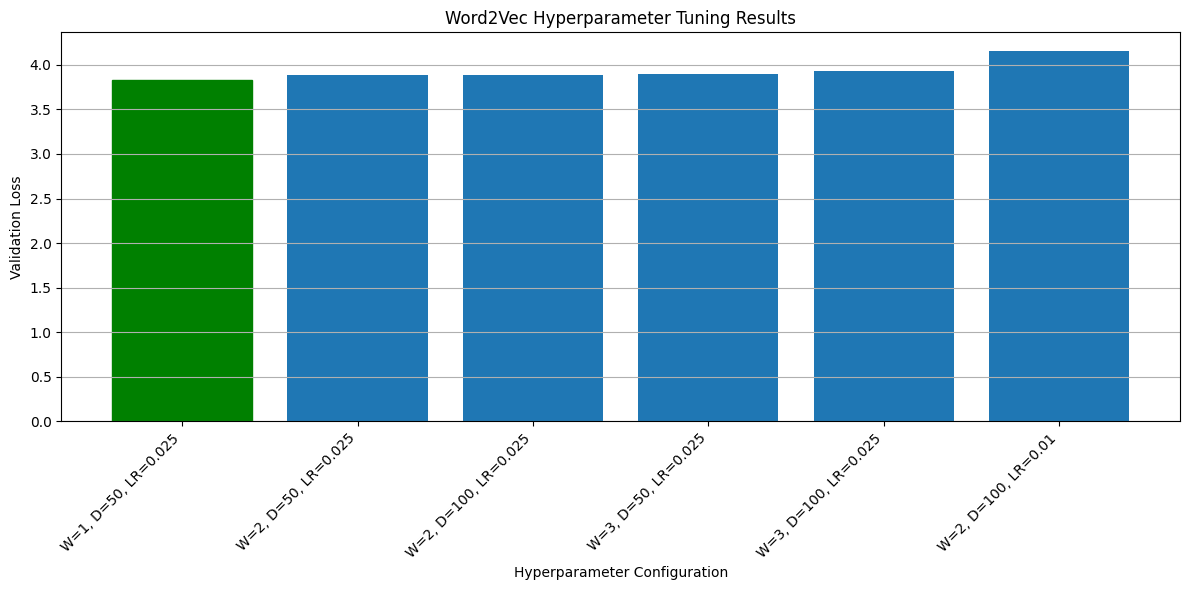

In [247]:

# Visualize Word2Vec hyperparameter tuning results

configuration_labels = [
    f"W={result['window']}, "
    f"D={result['dimension']}, "
    f"LR={result['learning_rate']}"
    for result in results
]

validation_values = [
    result["validation_loss"]
    for result in results
]

plt.figure(figsize=(12, 6))

bars = plt.bar(
    configuration_labels,
    validation_values
)

# Highlight the best configuration
bars[0].set_color("green")

plt.xlabel("Hyperparameter Configuration")
plt.ylabel("Validation Loss")
plt.title("Word2Vec Hyperparameter Tuning Results")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


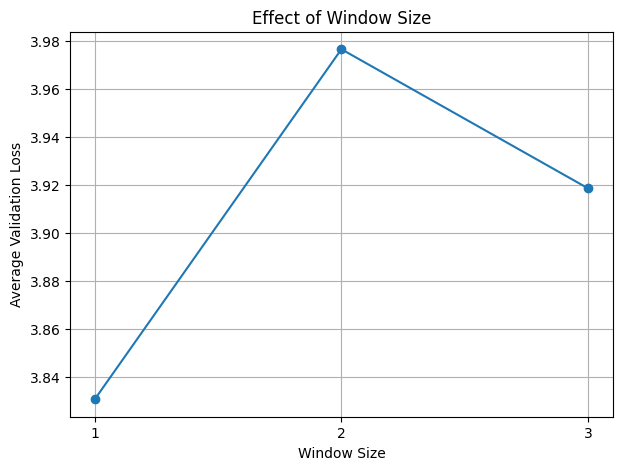

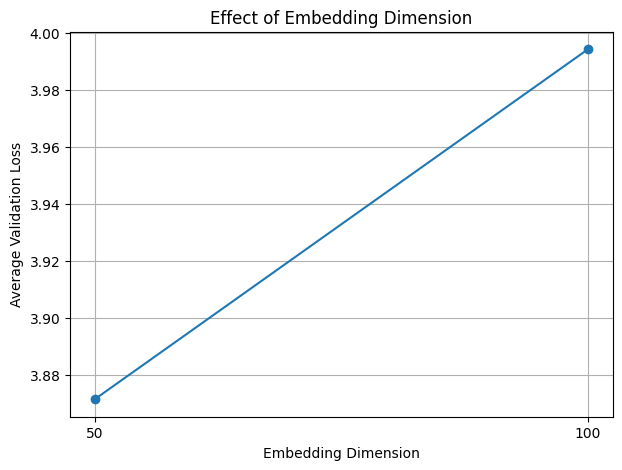

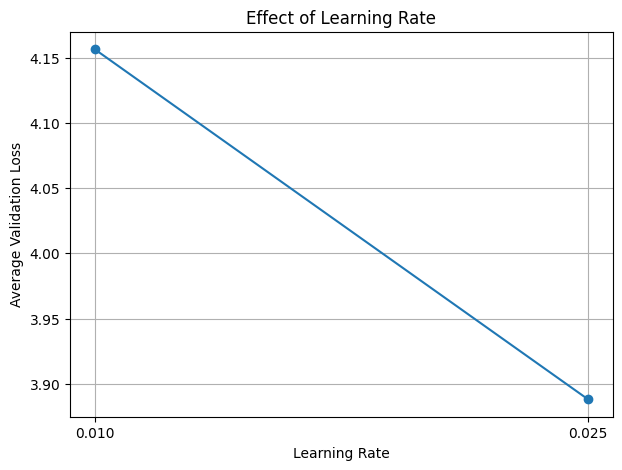

In [248]:

# 1. Effect of window size

window_values = sorted(set(r["window"] for r in results))

window_losses = [
    np.mean([
        r["validation_loss"]
        for r in results
        if r["window"] == window
    ])
    for window in window_values
]

plt.figure(figsize=(7, 5))

plt.plot(
    window_values,
    window_losses,
    marker="o"
)

plt.xlabel("Window Size")
plt.ylabel("Average Validation Loss")
plt.title("Effect of Window Size")
plt.xticks(window_values)
plt.grid(True)
plt.show()


# 2. Effect of embedding dimension

dimension_values = sorted(set(r["dimension"] for r in results))

dimension_losses = [
    np.mean([
        r["validation_loss"]
        for r in results
        if r["dimension"] == dimension
    ])
    for dimension in dimension_values
]

plt.figure(figsize=(7, 5))

plt.plot(
    dimension_values,
    dimension_losses,
    marker="o"
)

plt.xlabel("Embedding Dimension")
plt.ylabel("Average Validation Loss")
plt.title("Effect of Embedding Dimension")
plt.xticks(dimension_values)
plt.grid(True)
plt.show()


# 3. Effect of learning rate

learning_rate_values = sorted(set(r["learning_rate"] for r in results))

learning_rate_losses = [
    np.mean([
        r["validation_loss"]
        for r in results
        if r["learning_rate"] == rate
    ])
    for rate in learning_rate_values
]

plt.figure(figsize=(7, 5))

plt.plot(
    learning_rate_values,
    learning_rate_losses,
    marker="o"
)

plt.xlabel("Learning Rate")
plt.ylabel("Average Validation Loss")
plt.title("Effect of Learning Rate")
plt.xticks(learning_rate_values)
plt.grid(True)
plt.show()


In [249]:
training_pairs = generate_pairs(
    train_ids,
    window_size
)

validation_pairs = generate_pairs(
    validation_ids,
    window_size
)

# Fixed validation negatives
validation_negatives = generate_validation_negatives(
    validation_pairs,
    negative_distribution,
    negative_samples,
    seed=42
)

print("Final training pairs:", len(training_pairs))
print("Final validation pairs:", len(validation_pairs))
rng = np.random.default_rng(42)

input_embeddings = rng.uniform(
    -0.5 / embedding_dim,
    0.5 / embedding_dim,
    (vocab_size, embedding_dim)
)

output_embeddings = np.zeros(
    (vocab_size, embedding_dim)
)

print("Input embedding shape:", input_embeddings.shape)
print("Output embedding shape:", output_embeddings.shape)

Final training pairs: 292320
Final validation pairs: 68484
Input embedding shape: (8456, 50)
Output embedding shape: (8456, 50)


In [250]:
# Create reproducible subsets for faster final training

max_training_pairs = 50000
max_validation_pairs = 10000

subset_rng = np.random.default_rng(42)

# Training subset
if len(training_pairs) > max_training_pairs:

    training_indices = subset_rng.choice(
        len(training_pairs),
        max_training_pairs,
        replace=False
    )

    fast_training_pairs = [
        training_pairs[i] for i in training_indices
    ]

else:
    fast_training_pairs = training_pairs


# Validation subset
if len(validation_pairs) > max_validation_pairs:

    validation_indices = subset_rng.choice(
        len(validation_pairs),
        max_validation_pairs,
        replace=False
    )

    fast_validation_pairs = [
        validation_pairs[i] for i in validation_indices
    ]

    # Keep the negative samples aligned with their validation pairs
    fast_validation_negatives = validation_negatives[validation_indices]

else:
    fast_validation_pairs = validation_pairs
    fast_validation_negatives = validation_negatives


print("Fast training pairs:", len(fast_training_pairs))
print("Fast validation pairs:", len(fast_validation_pairs))
print("Fast validation negatives:", fast_validation_negatives.shape)

Fast training pairs: 50000
Fast validation pairs: 10000
Fast validation negatives: (10000, 5)


In [251]:

training_losses = []
validation_losses = []

best_validation_loss = float("inf")
best_embeddings = None

min_improvement = 0.001
patience = 2
epochs_without_improvement = 0
max_epochs = 10

for epoch in range(max_epochs):

    training_loss = train_epoch(
        fast_training_pairs,
        input_embeddings,
        output_embeddings,
        negative_distribution,
        negative_samples,
        learning_rate,
        rng
    )

    validation_loss = calculate_validation_loss(
        fast_validation_pairs,
        fast_validation_negatives,
        input_embeddings,
        output_embeddings
    )

    training_losses.append(training_loss)
    validation_losses.append(validation_loss)

    print("Epoch:", epoch + 1)
    print("Training loss:", round(training_loss, 4))
    print("Validation loss:", round(validation_loss, 4))
    print("----------------------")

    # Check if validation loss improved enough
    improvement = best_validation_loss - validation_loss

    if improvement >= min_improvement:

        best_validation_loss = validation_loss
        best_embeddings = input_embeddings.copy()
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= patience:

        print("Early stopping: improvement is less than 0.001.")
        break

# Keep the best learned input embeddings
word2vec_embeddings = best_embeddings.copy()

print("Best validation loss:", best_validation_loss)
print("Epochs completed:", len(training_losses))
print("Final embedding shape:", word2vec_embeddings.shape)


Epoch: 1
Training loss: 4.1024
Validation loss: 3.9291
----------------------
Epoch: 2
Training loss: 3.7317
Validation loss: 3.5418
----------------------
Epoch: 3
Training loss: 3.4065
Validation loss: 3.3047
----------------------
Epoch: 4
Training loss: 3.1794
Validation loss: 3.1391
----------------------
Epoch: 5
Training loss: 2.9924
Validation loss: 3.0057
----------------------
Epoch: 6
Training loss: 2.8346
Validation loss: 2.9133
----------------------
Epoch: 7
Training loss: 2.6881
Validation loss: 2.8357
----------------------
Epoch: 8
Training loss: 2.5688
Validation loss: 2.7706
----------------------
Epoch: 9
Training loss: 2.4603
Validation loss: 2.7302
----------------------
Epoch: 10
Training loss: 2.3619
Validation loss: 2.6927
----------------------
Best validation loss: 2.692657188111866
Epochs completed: 10
Final embedding shape: (8456, 50)


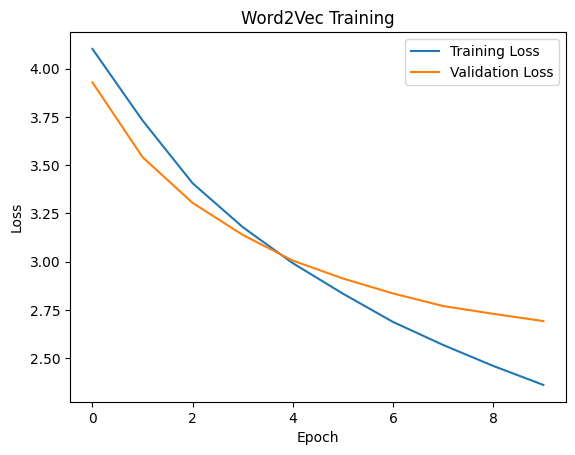

In [252]:
plt.plot(training_losses, label="Training Loss")
plt.plot(validation_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Word2Vec Training")

plt.legend()
plt.show()

In [253]:
def dense_cosine(vector1, vector2):

    norm1 = np.linalg.norm(vector1)
    norm2 = np.linalg.norm(vector2)

    if norm1 == 0 or norm2 == 0:
        return 0

    return np.dot(vector1, vector2) / (norm1 * norm2)

In [254]:
def find_word2vec_neighbors(query_word, embeddings, number=5):

    if query_word not in word_to_id:
        return []

    query_id = word_to_id[query_word]

    similarities = []

    for word in word_to_id:

        word_id = word_to_id[word]

        if word == query_word:
            continue

        similarity = dense_cosine(
            embeddings[query_id],
            embeddings[word_id]
        )

        similarities.append((word, similarity))

    similarities.sort(key=lambda x: x[1], reverse=True)

    return similarities[:number]

In [255]:
print("PPMI dimensions:", len(vocabulary), "x", len(vocabulary))

print("TF-IDF dimensions:", len(vocabulary), "x", number_of_documents)

print("Word2Vec dimensions:", word2vec_embeddings.shape)

PPMI dimensions: 8456 x 8456
TF-IDF dimensions: 8456 x 7149
Word2Vec dimensions: (8456, 50)


In [256]:
ppmi_nonzero = 0

for word in ppmi_results[window_size]:

    ppmi_nonzero += len(ppmi_results[window_size][word])

tfidf_nonzero = 0

for word in tfidf_vectors:

    tfidf_nonzero += len(tfidf_vectors[word])

word2vec_nonzero = np.count_nonzero(word2vec_embeddings)

print("PPMI non-zero values:", ppmi_nonzero)
print("TF-IDF non-zero values:", tfidf_nonzero)
print("Word2Vec non-zero values:", word2vec_nonzero)

PPMI non-zero values: 131102
TF-IDF non-zero values: 143784
Word2Vec non-zero values: 422800


In [257]:
vocab_size = len(vocabulary)

ppmi_density = ppmi_nonzero / (vocab_size * vocab_size)

tfidf_density = tfidf_nonzero / (vocab_size * number_of_documents)

word2vec_density = word2vec_nonzero / word2vec_embeddings.size

print("PPMI density:", ppmi_density)
print("TF-IDF density:", tfidf_density)
print("Word2Vec density:", word2vec_density)

PPMI density: 0.0018334934737019232
TF-IDF density: 0.002378484304822356
Word2Vec density: 1.0


In [258]:
ppmi_size = vocab_size * vocab_size * 8 / (1024 ** 2)

tfidf_size = vocab_size * number_of_documents * 8 / (1024 ** 2)

word2vec_size = word2vec_embeddings.size * 8 / (1024 ** 2)

print("PPMI dense storage :", ppmi_size)
print("TF-IDF dense storage :", tfidf_size)
print("Word2Vec storage :", word2vec_size)

PPMI dense storage : 545.53173828125
TF-IDF dense storage : 461.21173095703125
Word2Vec storage : 3.2257080078125


# Part 2: Hidden Markov Model and Viterbi

A bigram HMM POS tagger:
- **Initial** $\pi(t) = P(t \text{ starts a sentence})$
- **Transition** $A(t' \to t) = P(t \mid t')$
- **Emission** $B(t \to w) = P(w \mid t)$

Viterbi finds the tag sequence that maximizes $\pi(t_1)B(t_1 \to w_1)\prod_{i>1} A(t_{i-1} \to t_i)B(t_i \to w_i)$.

We reuse Part 1's train / validation / test split, but **not** its preprocessing: tagging needs punctuation (it has its own tags) and capitalization (a strong hint for proper nouns).

### 2.1 Tokens and POS tags
Convert tag IDs to names. Chunk labels are not used.

In [47]:
pos_tag_names = dataset["train"].features["pos_tags"].feature.names


def get_tokens_and_tags(data_split):
    # each split ends with one empty sentence, which is skipped
    sentences, tag_sequences = [], []
    for tokens, tag_ids in zip(data_split["tokens"], data_split["pos_tags"]):
        if len(tokens) > 0:
            sentences.append(list(tokens))
            tag_sequences.append([pos_tag_names[tag_id] for tag_id in tag_ids])
    return sentences, tag_sequences


pos_train_sentences, pos_train_tags = get_tokens_and_tags(train_data)
pos_validation_sentences, pos_validation_tags = get_tokens_and_tags(validation_data)
pos_test_sentences, pos_test_tags = get_tokens_and_tags(test_data)

for sentences, tag_sequences in [
    (pos_train_sentences, pos_train_tags),
    (pos_validation_sentences, pos_validation_tags),
    (pos_test_sentences, pos_test_tags),
]:
    assert all(len(s) == len(t) for s, t in zip(sentences, tag_sequences))

print("Number of POS tags:", len(pos_tag_names))
print("Sentences  train / validation / test:",
      len(pos_train_sentences), "/", len(pos_validation_sentences), "/", len(pos_test_sentences))
print("\nExample:")
print(list(zip(pos_train_sentences[0], pos_train_tags[0])))

Number of POS tags: 44
Sentences  train / validation / test: 7149 / 1787 / 2012

Example:
[('Congress', 'NNP'), ('has', 'VBZ'), ('enough', 'JJ'), ('difficulty', 'NN'), ('dealing', 'VBG'), ('with', 'IN'), ('the', 'DT'), ('realities', 'NNS'), ('of', 'IN'), ('the', 'DT'), ('world', 'NN'), ('as', 'IN'), ('it', 'PRP'), ('currently', 'RB'), ('exists', 'VBZ'), ('.', '.')]


### 2.2 Training: counting + smoothing

**Unknown words:** training words seen fewer than `min_word_frequency` times become `<UNK>`, so the model learns which tags rare words take. At test time, any word not in the vocabulary is treated as `<UNK>`.

**Add-k smoothing** avoids zero probabilities:

$$\pi(t) = \frac{C(\text{start}, t) + \alpha}{N + \alpha |T|} \qquad
A(t' \to t) = \frac{C(t', t) + \alpha}{C(t') + \alpha |T|} \qquad
B(t \to w) = \frac{C(t, w) + \beta}{C(t) + \beta |V|}$$

All probabilities are stored as logs to avoid underflow.

In [48]:
UNK_TOKEN = "<UNK>"


def train_hmm(sentences, tag_sequences, min_word_frequency=2, alpha=0.1, beta=0.1):
    word_frequencies = Counter(word for sentence in sentences for word in sentence)
    vocabulary = {word for word, count in word_frequencies.items() if count >= min_word_frequency}
    vocabulary.add(UNK_TOKEN)

    tags = sorted({tag for sequence in tag_sequences for tag in sequence})
    tag_to_index = {tag: index for index, tag in enumerate(tags)}
    number_of_tags = len(tags)

    initial_counts = np.zeros(number_of_tags)
    transition_counts = np.zeros((number_of_tags, number_of_tags))  # rows: previous tag, columns: current tag
    emission_counts = {tag: Counter() for tag in tags}

    for sentence, sentence_tags in zip(sentences, tag_sequences):
        tag_ids = [tag_to_index[tag] for tag in sentence_tags]

        initial_counts[tag_ids[0]] += 1

        for previous_id, current_id in zip(tag_ids[:-1], tag_ids[1:]):
            transition_counts[previous_id, current_id] += 1

        for word, tag in zip(sentence, sentence_tags):
            if word not in vocabulary:
                word = UNK_TOKEN
            emission_counts[tag][word] += 1

    # add-k smoothing, stored as log probabilities
    log_initial = np.log(
        (initial_counts + alpha) / (initial_counts.sum() + alpha * number_of_tags)
    )
    log_transition = np.log(
        (transition_counts + alpha)
        / (transition_counts.sum(axis=1, keepdims=True) + alpha * number_of_tags)
    )

    log_emission = {}
    log_unk_emission = {}  # for vocabulary words never seen with this tag
    for tag in tags:
        denominator = sum(emission_counts[tag].values()) + beta * len(vocabulary)
        log_emission[tag] = {
            word: np.log((count + beta) / denominator)
            for word, count in emission_counts[tag].items()
        }
        log_unk_emission[tag] = np.log(beta / denominator)

    return {
        "tags": tags,
        "vocabulary": vocabulary,
        "log_initial": log_initial,
        "log_transition": log_transition,
        "log_emission": log_emission,
        "log_unk_emission": log_unk_emission,
    }

### 2.3 Viterbi decoding

`scores[i, t]` is the best log probability of tagging words $1..i$ with the last tag $t$:

$$\text{scores}[i, t] = \max_{t'} \big(\text{scores}[i-1, t'] + \log A(t' \to t)\big) + \log B(t \to w_i)$$

`backpointers` store the best $t'$, so the best path is recovered by walking back from the end. Cost: $O(n|T|^2)$.

In [49]:
def emission_scores(word, hmm):
    if word not in hmm["vocabulary"]:
        word = UNK_TOKEN
    return np.array([
        hmm["log_emission"][tag].get(word, hmm["log_unk_emission"][tag])
        for tag in hmm["tags"]
    ])


def viterbi(sentence, hmm):
    number_of_words = len(sentence)
    number_of_tags = len(hmm["tags"])
    scores = np.zeros((number_of_words, number_of_tags))
    backpointers = np.zeros((number_of_words, number_of_tags), dtype=int)

    scores[0] = hmm["log_initial"] + emission_scores(sentence[0], hmm)

    for i in range(1, number_of_words):
        # rows: previous tag, columns: current tag
        candidates = scores[i - 1][:, np.newaxis] + hmm["log_transition"]
        backpointers[i] = candidates.argmax(axis=0)
        scores[i] = candidates.max(axis=0) + emission_scores(sentence[i], hmm)

    best_path = [int(scores[-1].argmax())]
    for i in range(number_of_words - 1, 0, -1):
        best_path.append(int(backpointers[i, best_path[-1]]))
    best_path.reverse()

    return [hmm["tags"][tag_index] for tag_index in best_path]


def predict_sentences(sentences, hmm):
    return [viterbi(sentence, hmm) for sentence in sentences]

### 2.4 Evaluation metrics
- **Accuracy**: share of correctly tagged tokens.
- **Macro precision / recall / F1**: computed per tag, then averaged, so rare tags count as much as frequent ones. (Micro averages equal accuracy here, so they are skipped.)
- Reported separately for **known** and **unknown** tokens (unknown = not in the HMM vocabulary: unseen in training, or seen fewer than `min_word_frequency` times).

In [50]:
def calculate_metrics(true_tags, predicted_tags):
    if not true_tags:
        return None

    true_counts = Counter(true_tags)            # TP + FN per tag
    predicted_counts = Counter(predicted_tags)  # TP + FP per tag
    correct_counts = Counter(t for t, p in zip(true_tags, predicted_tags) if t == p)  # TP per tag

    per_tag = {}
    for tag in sorted(true_counts | predicted_counts):
        precision = correct_counts[tag] / predicted_counts[tag] if predicted_counts[tag] else 0.0
        recall = correct_counts[tag] / true_counts[tag] if true_counts[tag] else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        per_tag[tag] = {"precision": precision, "recall": recall, "f1": f1, "support": true_counts[tag]}

    return {
        "accuracy": sum(correct_counts.values()) / len(true_tags),
        "macro_precision": np.mean([s["precision"] for s in per_tag.values()]),
        "macro_recall": np.mean([s["recall"] for s in per_tag.values()]),
        "macro_f1": np.mean([s["f1"] for s in per_tag.values()]),
        "per_tag": per_tag,
    }


def evaluate_hmm(sentences, true_tag_sequences, predicted_tag_sequences, vocabulary):
    groups = {"overall": ([], []), "known": ([], []), "unknown": ([], [])}

    for sentence, true_tags, predicted_tags in zip(sentences, true_tag_sequences, predicted_tag_sequences):
        for word, true_tag, predicted_tag in zip(sentence, true_tags, predicted_tags):
            group = "known" if word in vocabulary else "unknown"
            for name in ("overall", group):
                groups[name][0].append(true_tag)
                groups[name][1].append(predicted_tag)

    results = {name: calculate_metrics(true, predicted) for name, (true, predicted) in groups.items()}
    results["unknown_token_count"] = len(groups["unknown"][0])
    results["known_token_count"] = len(groups["known"][0])
    return results


def print_metrics(results, title):
    print(title)
    print(f"  Token accuracy:  {results['accuracy']:.4f}")
    print(f"  Macro precision: {results['macro_precision']:.4f}")
    print(f"  Macro recall:    {results['macro_recall']:.4f}")
    print(f"  Macro F1:        {results['macro_f1']:.4f}")

### 2.5 Tuning on validation
- `min_word_frequency`: rarer words become `<UNK>`.
- `beta`: emission smoothing.
- `alpha` is fixed at 0.1: it only smooths the small 44×44 tag tables, which have plenty of training data.

We select by **macro F1**, not accuracy. With `min_word_frequency = 1` no training word becomes `<UNK>`, so unknown words are tagged badly (about 30% accuracy instead of 50%). Overall accuracy hardly notices this; macro F1 does.

In [51]:
ALPHA = 0.1
minimum_frequency_values = [1, 2, 3]
beta_values = [0.0001, 0.001, 0.01, 0.1, 1.0]

tuning_results = []

for min_word_frequency in minimum_frequency_values:
    for beta in beta_values:
        model = train_hmm(pos_train_sentences, pos_train_tags, min_word_frequency, ALPHA, beta)
        predictions = predict_sentences(pos_validation_sentences, model)
        metrics = evaluate_hmm(pos_validation_sentences, pos_validation_tags, predictions, model["vocabulary"])

        tuning_results.append({
            "min_word_frequency": min_word_frequency,
            "beta": beta,
            "accuracy": metrics["overall"]["accuracy"],
            "macro_f1": metrics["overall"]["macro_f1"],
            "unknown_accuracy": metrics["unknown"]["accuracy"],
        })

tuning_results.sort(key=lambda result: result["macro_f1"], reverse=True)

print(f"{'min_freq':>8} {'beta':>6} | {'macro F1':>8} {'accuracy':>8} {'UNK acc':>8}")
for result in tuning_results:
    print(f"{result['min_word_frequency']:>8} {result['beta']:>6} | "
          f"{result['macro_f1']:>8.4f} {result['accuracy']:>8.4f} {result['unknown_accuracy']:>8.4f}")

best_config = {
    "min_word_frequency": tuning_results[0]["min_word_frequency"],
    "alpha": ALPHA,
    "beta": tuning_results[0]["beta"],
}
print("\nSelected:", best_config)

min_freq   beta | macro F1 accuracy  UNK acc
       2  0.001 |   0.8939   0.9398   0.5028
       2 0.0001 |   0.8921   0.9394   0.5006
       2   0.01 |   0.8917   0.9393   0.5031
       3 0.0001 |   0.8895   0.9295   0.5034
       3  0.001 |   0.8883   0.9296   0.5034
       3   0.01 |   0.8852   0.9291   0.5038
       2    0.1 |   0.8787   0.9339   0.5025
       3    0.1 |   0.8689   0.9246   0.5030
       1    0.1 |   0.8552   0.9353   0.3570
       1   0.01 |   0.8287   0.9398   0.2883
       1  0.001 |   0.7763   0.9370   0.2230
       1 0.0001 |   0.7696   0.9354   0.1991
       3    1.0 |   0.7635   0.8915   0.4859
       2    1.0 |   0.7632   0.8957   0.4916
       1    1.0 |   0.7423   0.8913   0.3770

Selected: {'min_word_frequency': 2, 'alpha': 0.1, 'beta': 0.001}


Left: too much emission smoothing (`beta = 1`) hurts overall accuracy. Right: `min_word_frequency = 1` breaks unknown-word tagging.

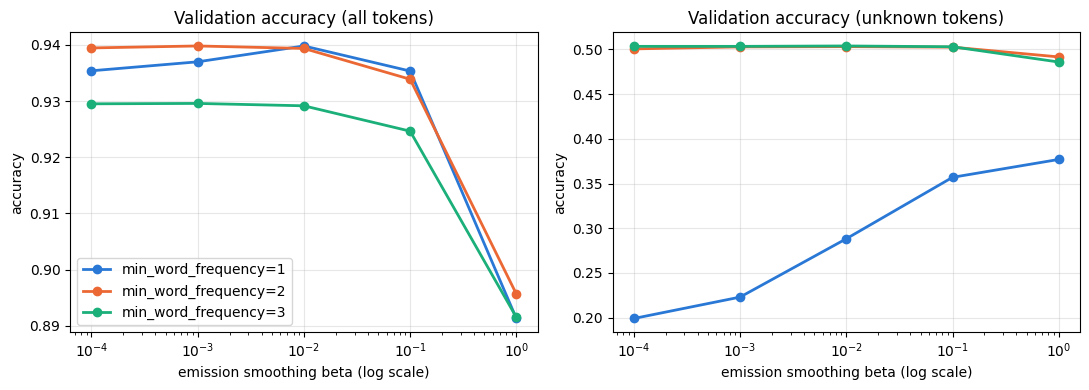

In [52]:
KNOWN_COLOR, UNKNOWN_COLOR = "#2a78d6", "#eb6834"

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for min_word_frequency, color in zip(minimum_frequency_values, ["#2a78d6", "#eb6834", "#1baf7a"]):
    rows = sorted((r for r in tuning_results if r["min_word_frequency"] == min_word_frequency),
                  key=lambda r: r["beta"])
    betas = [r["beta"] for r in rows]
    axes[0].plot(betas, [r["accuracy"] for r in rows], marker="o", lw=2, color=color,
                 label=f"min_word_frequency={min_word_frequency}")
    axes[1].plot(betas, [r["unknown_accuracy"] for r in rows], marker="o", lw=2, color=color)

axes[0].set_title("Validation accuracy (all tokens)")
axes[1].set_title("Validation accuracy (unknown tokens)")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("emission smoothing beta (log scale)")
    ax.set_ylabel("accuracy")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

### 2.6 Final model
Trained on the training split only, so Part 3 can still tune on validation.

In [53]:
final_hmm = train_hmm(pos_train_sentences, pos_train_tags, **best_config)

print("Selected settings:", best_config)
print("Number of tags:", len(final_hmm["tags"]))
print("HMM vocabulary size (including <UNK>):", len(final_hmm["vocabulary"]))

Selected settings: {'min_word_frequency': 2, 'alpha': 0.1, 'beta': 0.001}
Number of tags: 44
HMM vocabulary size (including <UNK>): 8457


**Viterbi check:** for a short sentence, score every possible tag sequence and confirm Viterbi picks the best one.

In [54]:
from itertools import product


def sequence_log_probability(sentence, tag_sequence, hmm):
    tag_ids = [hmm["tags"].index(tag) for tag in tag_sequence]
    total = hmm["log_initial"][tag_ids[0]]
    for previous_id, current_id in zip(tag_ids[:-1], tag_ids[1:]):
        total += hmm["log_transition"][previous_id, current_id]
    for word, tag_id in zip(sentence, tag_ids):
        total += emission_scores(word, hmm)[tag_id]
    return total


check_sentence = ["The", "stock", "rose"]

brute_force_best = max(
    product(final_hmm["tags"], repeat=len(check_sentence)),
    key=lambda tags: sequence_log_probability(check_sentence, tags, final_hmm),
)
viterbi_best = viterbi(check_sentence, final_hmm)

print("Brute force:", list(brute_force_best))
print("Viterbi:    ", viterbi_best)
assert list(brute_force_best) == viterbi_best

Brute force: ['DT', 'NN', 'VBD']
Viterbi:     ['DT', 'NN', 'VBD']


**Learned transitions** among the 15 most frequent tags. Expected patterns appear: `DT → NN`, `TO → VB`, `JJ → NN`.

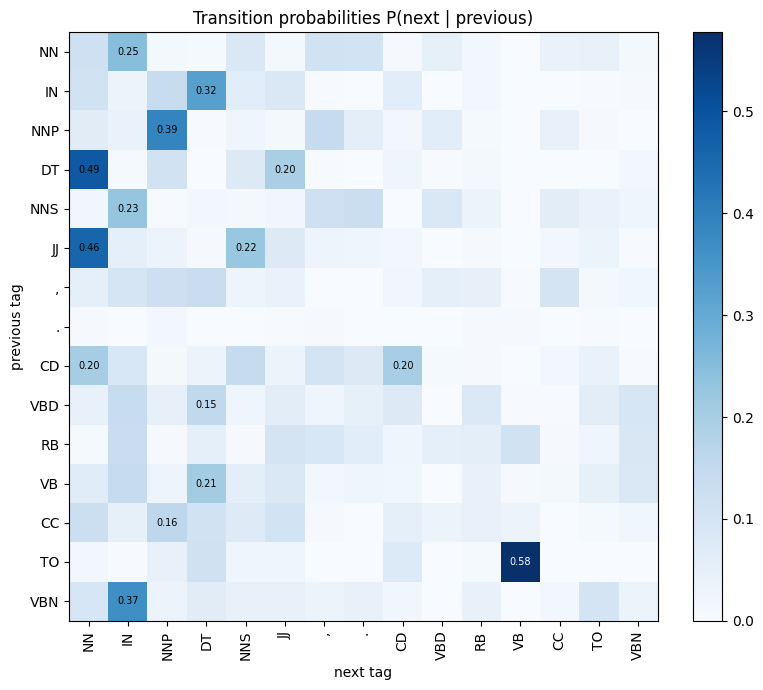

In [55]:
tag_frequencies = Counter(tag for sequence in pos_train_tags for tag in sequence)
frequent_tags = [tag for tag, _ in tag_frequencies.most_common(15)]
frequent_ids = [final_hmm["tags"].index(tag) for tag in frequent_tags]
transition_probabilities = np.exp(final_hmm["log_transition"][np.ix_(frequent_ids, frequent_ids)])

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(transition_probabilities, cmap="Blues", vmin=0)
ax.set_xticks(range(len(frequent_tags)), frequent_tags, rotation=90)
ax.set_yticks(range(len(frequent_tags)), frequent_tags)
ax.set_xlabel("next tag")
ax.set_ylabel("previous tag")
ax.set_title("Transition probabilities P(next | previous)")
for row in range(len(frequent_tags)):
    for col in range(len(frequent_tags)):
        value = transition_probabilities[row, col]
        if value >= 0.15:
            ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if value > 0.5 else "black")
fig.colorbar(image, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

**Tags expected for an unknown word**, before context is used: $P(t \mid \texttt{<UNK>}) \propto P(\texttt{<UNK>} \mid t)\,P(t)$.

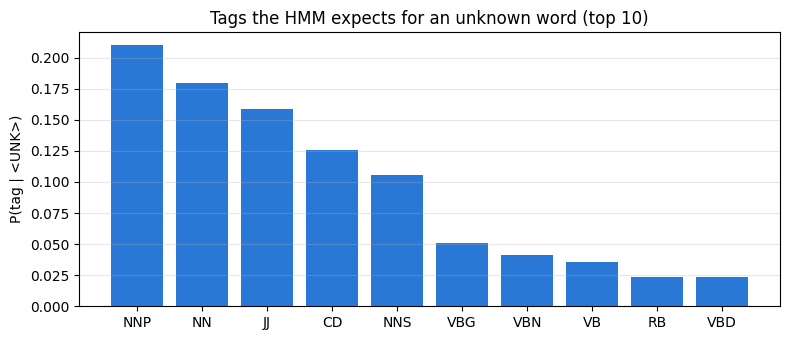

In [56]:
unk_emission = np.array([final_hmm["log_emission"][tag].get(UNK_TOKEN, final_hmm["log_unk_emission"][tag])
                         for tag in final_hmm["tags"]])
tag_prior = np.array([tag_frequencies[tag] for tag in final_hmm["tags"]], dtype=float)
unk_tag_distribution = np.exp(unk_emission) * tag_prior
unk_tag_distribution /= unk_tag_distribution.sum()

top = np.argsort(unk_tag_distribution)[::-1][:10]
plt.figure(figsize=(8, 3.5))
plt.bar([final_hmm["tags"][i] for i in top], unk_tag_distribution[top], color=KNOWN_COLOR)
plt.ylabel("P(tag | <UNK>)")
plt.title("Tags the HMM expects for an unknown word (top 10)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 2.7 Test results
The test set is used once, with the settings chosen on validation.

In [57]:
test_predictions = predict_sentences(pos_test_sentences, final_hmm)
test_metrics = evaluate_hmm(pos_test_sentences, pos_test_tags, test_predictions, final_hmm["vocabulary"])

total_tokens = test_metrics["known_token_count"] + test_metrics["unknown_token_count"]
print(f"Test tokens: {total_tokens}, unknown: {test_metrics['unknown_token_count']} "
      f"({100 * test_metrics['unknown_token_count'] / total_tokens:.1f}%)\n")
print_metrics(test_metrics["overall"], "All tokens")
print_metrics(test_metrics["known"], "Known tokens")
print_metrics(test_metrics["unknown"], "Unknown tokens")

Test tokens: 47377, unknown: 5063 (10.7%)

All tokens
  Token accuracy:  0.9324
  Macro precision: 0.9215
  Macro recall:    0.9103
  Macro F1:        0.9115
Known tokens
  Token accuracy:  0.9806
  Macro precision: 0.9488
  Macro recall:    0.9684
  Macro F1:        0.9538
Unknown tokens
  Token accuracy:  0.5295
  Macro precision: 0.2089
  Macro recall:    0.1883
  Macro F1:        0.1907


**Known vs. unknown words:** most of the difficulty comes from unknown words.

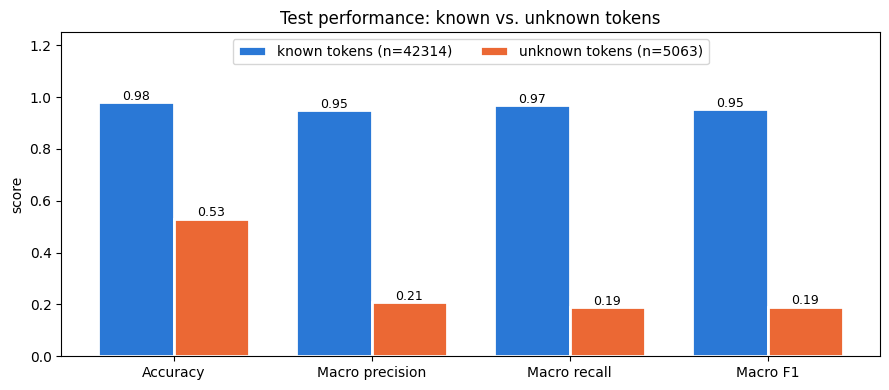

In [58]:
metric_keys = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]
metric_labels = ["Accuracy", "Macro precision", "Macro recall", "Macro F1"]
positions = np.arange(len(metric_keys))
bar_width = 0.38

plt.figure(figsize=(9, 4))
for offset, group, color in [(-bar_width / 2, "known", KNOWN_COLOR), (bar_width / 2, "unknown", UNKNOWN_COLOR)]:
    values = [test_metrics[group][key] for key in metric_keys]
    bars = plt.bar(positions + offset, values, bar_width, color=color, edgecolor="white", linewidth=2,
                   label=f"{group} tokens (n={test_metrics[group + '_token_count']})")
    for bar, value in zip(bars, values):
        plt.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.2f}", ha="center", fontsize=9)

plt.xticks(positions, metric_labels)
plt.ylim(0, 1.25)
plt.ylabel("score")
plt.title("Test performance: known vs. unknown tokens")
plt.legend(loc="upper center", ncol=2)
plt.tight_layout()
plt.show()

**F1 per tag** (n = test count). Rare tags like `RP`, `UH`, `FW` lower macro F1 but barely affect accuracy.

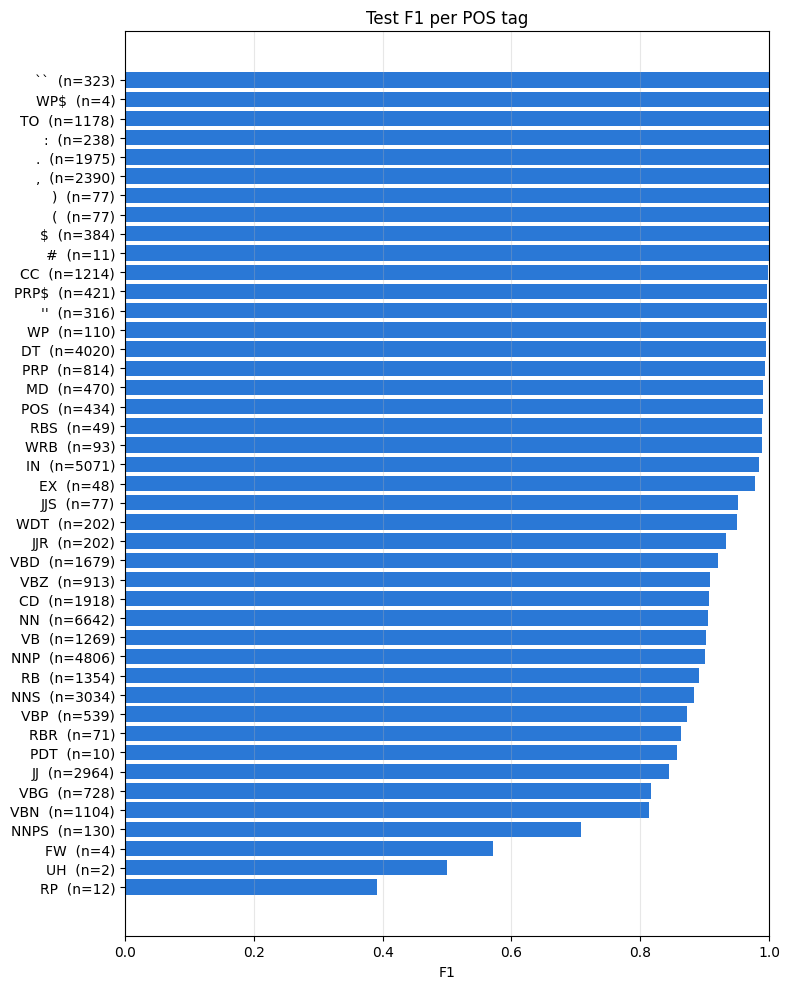

In [59]:
per_tag = test_metrics["overall"]["per_tag"]
ordered_tags = sorted(per_tag, key=lambda tag: per_tag[tag]["f1"])

plt.figure(figsize=(8, 10))
plt.barh([f"{tag}  (n={per_tag[tag]['support']})" for tag in ordered_tags],
         [per_tag[tag]["f1"] for tag in ordered_tags], color=KNOWN_COLOR)
plt.xlim(0, 1)
plt.xlabel("F1")
plt.title("Test F1 per POS tag")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Most frequent errors**, split by known / unknown word.

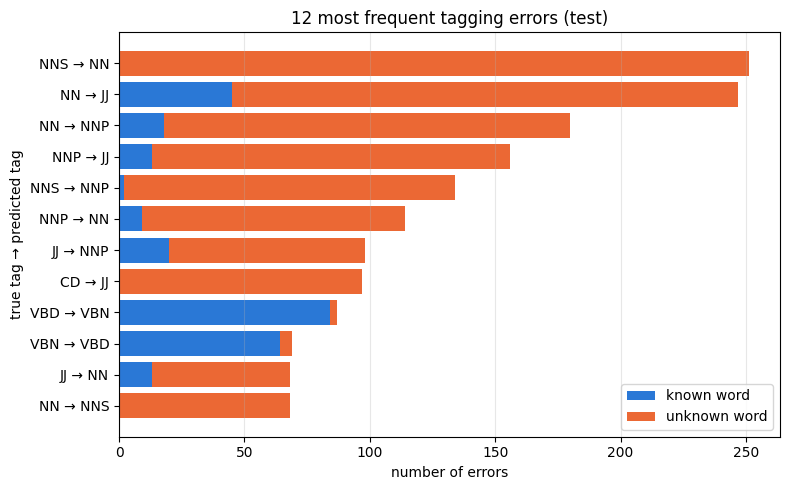

Errors on unknown words: 2382 of 3201 (74.4%), although unknown words are only 10.7% of the tokens


In [60]:
confusions = {"known": Counter(), "unknown": Counter()}
for sentence, true_tags, predicted_tags in zip(pos_test_sentences, pos_test_tags, test_predictions):
    for word, true_tag, predicted_tag in zip(sentence, true_tags, predicted_tags):
        if true_tag != predicted_tag:
            group = "known" if word in final_hmm["vocabulary"] else "unknown"
            confusions[group][(true_tag, predicted_tag)] += 1

top_confusions = [pair for pair, _ in (confusions["known"] + confusions["unknown"]).most_common(12)][::-1]
labels = [f"{true_tag} → {predicted_tag}" for true_tag, predicted_tag in top_confusions]
known_counts = [confusions["known"][pair] for pair in top_confusions]
unknown_counts = [confusions["unknown"][pair] for pair in top_confusions]

plt.figure(figsize=(8, 5))
plt.barh(labels, known_counts, color=KNOWN_COLOR, label="known word")
plt.barh(labels, unknown_counts, left=known_counts, color=UNKNOWN_COLOR, label="unknown word")
plt.xlabel("number of errors")
plt.ylabel("true tag → predicted tag")
plt.title("12 most frequent tagging errors (test)")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

unknown_errors = sum(confusions["unknown"].values())
total_errors = unknown_errors + sum(confusions["known"].values())
print(f"Errors on unknown words: {unknown_errors} of {total_errors} ({100 * unknown_errors / total_errors:.1f}%), "
      f"although unknown words are only {100 * test_metrics['unknown_token_count'] / total_tokens:.1f}% of the tokens")

### 2.8 Example errors
`[UNK]` marks words outside the HMM vocabulary.

In [61]:
number_of_examples = 12
shown = 0

for sentence, true_tags, predicted_tags in zip(pos_test_sentences, pos_test_tags, test_predictions):
    for i, (word, true_tag, predicted_tag) in enumerate(zip(sentence, true_tags, predicted_tags)):
        if true_tag != predicted_tag and shown < number_of_examples:
            status = "[UNK]" if word not in final_hmm["vocabulary"] else "     "
            context = " ".join(sentence[max(0, i - 3): i + 4])
            print(f"{status} {word:<16} true={true_tag:<5} predicted={predicted_tag:<5} | {context}")
            shown += 1

[UNK] Tulsa            true=NNP   predicted=JJ    | International Corp. 's Tulsa unit said it
[UNK] extending        true=VBG   predicted=VBD   | a tentative agreement extending its contract with
[UNK] jetliners        true=NNS   predicted=CD    | Boeing 's 747 jetliners .
[UNK] shipsets         true=NNS   predicted=NN    | 200 additional so-called shipsets for the planes
[UNK] bulkheads        true=NNS   predicted=NN    | 's two major bulkheads , a pressure
[UNK] torque           true=NN    predicted=JJ    | pressure floor , torque box , fixed
[UNK] edges            true=NNS   predicted=NN    | , fixed leading edges for the wings
[UNK] wings            true=NNS   predicted=NN    | edges for the wings and an aft
[UNK] aft              true=JJ    predicted=NNP   | wings and an aft keel beam .
[UNK] keel             true=NN    predicted=NNP   | and an aft keel beam .
[UNK] beam             true=NN    predicted=NNP   | an aft keel beam .
[UNK] 793              true=CD    predicted=NN    |

## Part 2: Summary

**Settings (chosen on validation):** `min_word_frequency = 2`, `alpha = 0.1`, `beta = 0.001`.

| Test | Tokens | Accuracy | Macro P | Macro R | Macro F1 |
|---|---|---|---|---|---|
| All | 47,377 | 0.932 | 0.922 | 0.910 | 0.912 |
| Known | 42,314 | 0.981 | 0.949 | 0.968 | 0.954 |
| Unknown | 5,063 (10.7%) | 0.530 | 0.209 | 0.188 | 0.191 |

**Takeaways**
- Known words are tagged very well (98%); their errors are real ambiguities such as `VBD ↔ VBN`.
- Unknown words are 10.7% of the tokens but cause ~74% of the errors. They all share one `<UNK>` emission, so their tag is decided by context and the general `<UNK>` tag distribution.
- Typical unknown errors: plural vs. singular (`wings` NNS → NN), noun vs. adjective vs. proper noun (`torque`, `aft`, `Tulsa`), numbers (`793` CD → NN).
- Small emission smoothing works best; `beta = 1` costs about 4 accuracy points.
- Part 3 targets exactly these unknown-word errors.

##  Part3 


In [298]:
for name, sentences, tag_sequences in [("train", train_sentences, train_tags),
                                       ("validation", validation_sentences, validation_tags),
                                       ("test", test_sentences, test_tags)]:
    assert [len(s) for s in sentences] == [len(t) for t in tag_sequences], name + " tokens and tags are misaligned"

## 1. Setup: representations, tag statistics, candidate pool

In [299]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

# Representations from Part 1
part3_representations = {
    "PMI": ppmi_results[window_size],
    "TF-IDF": tfidf_vectors,
    "Word2Vec": word2vec_embeddings
}
representation_names = ["PMI", "TF-IDF", "Word2Vec"]
sparse_representation_names = ["PMI", "TF-IDF"]

CONTEXT_WINDOW = window_size      # words before/after the unknown word that are used as context
POOL_SIZE = 5000                  # number of candidate neighbour words (cosine similarity is computed against these only)
MAX_NEIGHBORS = 20                # neighbours stored per unknown token; top_k <= MAX_NEIGHBORS is applied later

print("PMI representation words:", len(part3_representations["PMI"]))
print("TF-IDF representation words:", len(part3_representations["TF-IDF"]))
print("Word2Vec representation shape:", part3_representations["Word2Vec"].shape)
print("Context window:", CONTEXT_WINDOW)

PMI representation words: 8456
TF-IDF representation words: 8456
Word2Vec representation shape: (8456, 50)
Context window: 1


In [300]:
# POS counts of the training words (only words known to the HMM) and tag priors
word_tag_counts = defaultdict(Counter)
tag_counts = Counter()

for sentence, tags in zip(train_sentences, train_tags):
    for word, tag in zip(sentence, tags):

        tag_counts[tag] += 1

        # Store tag counts only for HMM words
        if word in final_hmm["vocabulary"]:
            word_tag_counts[word][tag] += 1

# total POS tag probability
total_tag_count = sum(tag_counts.values())
tag_priors = {
    tag: count / total_tag_count
    for tag, count in tag_counts.items()
}

hmm_tags = final_hmm["tags"]
prior_vector = np.array([tag_priors[tag] for tag in hmm_tags])

# Baseline emission of the <UNK> symbol (what the Part 2 Viterbi uses for every unknown word)
unk_log_emission = np.array([
    final_hmm["log_emission"][tag].get(
        UNK_TOKEN,
        final_hmm["log_unk_emission"][tag]
    )
    for tag in hmm_tags
])

print("Words with POS distributions:", len(word_tag_counts))
print("Number of tags:", len(hmm_tags))

Words with POS distributions: 8456
Number of tags: 44


**Candidate pool.** The same pool is used by the three representations (fair comparison): HMM-known words that have a vector in
every representation, keeping the 5,000 most frequent ones (frequent words have reliable POS statistics).

In [301]:
train_word_counts = Counter(
    word for sentence in train_sentences for word in sentence
)

common_candidates = (
    set(part3_representations["PMI"].keys())
    & set(part3_representations["TF-IDF"].keys())
    & set(word_to_id.keys())
    & set(final_hmm["vocabulary"])
    & set(word_tag_counts.keys())
)

top_candidate_words = sorted(
    common_candidates,
    key=lambda word: (-train_word_counts[word], word)
)[:POOL_SIZE]

print("Eligible common candidates:", len(common_candidates))
print("Candidate pool used:", len(top_candidate_words))

Eligible common candidates: 8456
Candidate pool used: 5000


## 2. Vector helpers

In [302]:
def get_word_vector(word, representation, representation_name):

    # sparse vectors
    if representation_name in sparse_representation_names:
        return representation.get(word, None)

    # dense vectors
    elif representation_name == "Word2Vec":
        if word not in word_to_id:
            return None
        return representation[word_to_id[word]]

    return None


def get_vector_norm(vector, representation_name):

    if vector is None:
        return 0.0

    if representation_name in sparse_representation_names:
        return math.sqrt(sum(value ** 2 for value in vector.values()))

    return float(np.linalg.norm(vector))


def normalize_vector(vector, representation_name):

    norm = get_vector_norm(vector, representation_name)

    if norm == 0:
        return None

    if representation_name in sparse_representation_names:
        return {feature: value / norm for feature, value in vector.items()}

    return vector / norm


def average_sparse_vectors(vectors):

    combined = defaultdict(float)

    if not vectors:
        return None

    for vector in vectors:
        for feature, value in vector.items():
            combined[feature] += value

    number_of_vectors = len(vectors)

    return {
        feature: value / number_of_vectors
        for feature, value in combined.items()
    }


def average_dense_vectors(vectors):

    if not vectors:
        return None

    return np.mean(vectors, axis=0)

## 3. Case B, option 1: average of the words around the unknown word

**Average mode (default idea):** every known context word contributes its own vector (length-normalised so each word counts equally),
and the vectors are averaged.


In [303]:

def get_context_words(sentence, position, context_window=2):
    start = max(0, position - context_window)
    end = min(len(sentence), position + context_window + 1)

    # only words known to the HMM are reliable context
    return [
        sentence[i]
        for i in range(start, end)
        if i != position and sentence[i] in final_hmm["vocabulary"]
    ]
def build_context_vector(
    sentence,
    position,
    representation,
    representation_name,
    context_window=2
):

    context_words = get_context_words(sentence, position, context_window)

    if not context_words:
        return None

    context_vectors = []

    for context_word in context_words:

        vector = get_word_vector(
            context_word,
            representation,
            representation_name
        )

        vector = normalize_vector(vector, representation_name)

        if vector is not None:
            context_vectors.append(vector)

    if not context_vectors:
        return None

    if representation_name in sparse_representation_names:
        return average_sparse_vectors(context_vectors)

    return average_dense_vectors(context_vectors)

## 4. Case B, option 2: suffix (and word-shape) matching

Words with the same ending usually share a POS tag (`-ing`, `-ed`, `-ly`, `-tion`, ...). The unknown word's context vector is then
compared **only with candidate words that have the same suffix**. If too few candidates share the suffix, all candidates are used.
The word shape (number / capitalised / other) works the same way: digits point to `CD`, a capital letter inside a sentence to `NNP`.

In [304]:
suffixes = [
    "tion", "sion", "ment", "ness", "ity",
    "ous", "ive", "able", "ible", "less",
    "ful", "ing", "ied", "ed", "ly",
    "er", "est", "en", "s"
]

MIN_CANDIDATES = 5       # a filter is used only if at least this many candidates remain
MIN_STEM_LENGTH = 3      # the stem before the suffix must have at least 3 letters (so "is", "was" are not "-s" words)


def get_suffix_candidate_words(
    target_word,
    candidate_words,
    min_candidates=MIN_CANDIDATES,
    min_stem_length=MIN_STEM_LENGTH
):

    target_word = target_word.lower()

    # Try the longest matching suffix first
    matching_suffixes = sorted(
        [
            suffix for suffix in suffixes
            if target_word.endswith(suffix)
            and len(target_word) - len(suffix) >= min_stem_length
        ],
        key=len,
        reverse=True
    )

    for suffix in matching_suffixes:

        candidates = [
            word for word in candidate_words
            if word.lower() != target_word
            and word.lower().endswith(suffix)
            and len(word) - len(suffix) >= min_stem_length
        ]

        if len(candidates) >= min_candidates:
            return candidates, suffix

    return [], None
candidate_selection_cache = {}


def select_candidate_words(
    target_word,
    position,
    candidate_words,
    use_suffix=True,
):

    cache_key = (target_word, position == 0, use_suffix)

    if cache_key in candidate_selection_cache:
        return candidate_selection_cache[cache_key]

    selected_words = candidate_words
    selection_parts = []
    # Same suffix
    if use_suffix:

        suffix_candidates, suffix = get_suffix_candidate_words(
            target_word,
            selected_words
        )

        if suffix_candidates:
            selected_words = suffix_candidates
            selection_parts.append("suffix")

    selection_name = "+".join(selection_parts) if selection_parts else "all"

    candidate_selection_cache[cache_key] = (selected_words, selection_name)

    return candidate_selection_cache[cache_key]

## 5. Cosine similarity search

For every representation a similarity index over the candidate pool is built once (vectors, norms, and for the sparse
representations an inverted index so only vectors that share a feature with the query are touched).
`similarity = dot(query, candidate) / (||query|| * ||candidate||)` is computed exactly as in Part 1.

In [305]:
def prepare_similarity_index(
    representation,
    representation_name,
    candidate_words
):

    candidate_vectors = {}
    candidate_norms = {}

    for word in candidate_words:

        vector = get_word_vector(
            word,
            representation,
            representation_name
        )

        norm = get_vector_norm(vector, representation_name)

        if norm == 0:
            continue

        candidate_vectors[word] = vector
        candidate_norms[word] = norm

    words = list(candidate_vectors.keys())

    similarity_index = {
        "words": words,
        "vectors": candidate_vectors,
        "norms": candidate_norms,
        "word_index": {word: i for i, word in enumerate(words)},
        "norm_array": np.array([candidate_norms[word] for word in words])
    }

    if representation_name in sparse_representation_names:

        feature_ids = defaultdict(list)
        feature_values = defaultdict(list)

        for i, word in enumerate(words):
            for feature, value in candidate_vectors[word].items():
                feature_ids[feature].append(i)
                feature_values[feature].append(value)

        similarity_index["feature_ids"] = {
            feature: np.array(ids) for feature, ids in feature_ids.items()
        }
        similarity_index["feature_values"] = {
            feature: np.array(values) for feature, values in feature_values.items()
        }

    else:

        similarity_index["matrix"] = np.array(
            [candidate_vectors[word] for word in words]
        )

    return similarity_index


def calculate_cosine_similarities(
    query_vector,
    representation_name,
    similarity_index
):

    query_norm = get_vector_norm(query_vector, representation_name)

    if query_norm == 0:
        return None

    if representation_name in sparse_representation_names:

        dot_products = np.zeros(len(similarity_index["words"]))

        for feature, query_value in query_vector.items():
            if feature in similarity_index["feature_ids"]:
                dot_products[similarity_index["feature_ids"][feature]] += (
                    query_value * similarity_index["feature_values"][feature]
                )

    else:

        dot_products = similarity_index["matrix"] @ query_vector

    return dot_products / (similarity_index["norm_array"] * query_norm)


def find_similar_words(
    query_vector,
    representation_name,
    number=10,
    similarity_index=None,
    candidate_words=None,
    exclude_words=None
):

    if query_vector is None:
        return []

    if similarity_index is None:
        raise ValueError("similarity_index is required.")

    similarities = calculate_cosine_similarities(
        query_vector,
        representation_name,
        similarity_index
    )

    if similarities is None:
        return []

    word_index = similarity_index["word_index"]

    # Search only the selected candidates (for example the words with the same suffix)
    if candidate_words is not None:

        allowed = np.zeros(len(similarities), dtype=bool)

        for word in candidate_words:
            if word in word_index:
                allowed[word_index[word]] = True

        similarities = np.where(allowed, similarities, 0.0)

    # Never return the context words themselves as neighbours
    if exclude_words:
        for word in exclude_words:
            if word in word_index:
                similarities[word_index[word]] = 0.0

    # Keep only positive similarities
    positive = np.flatnonzero(similarities > 0)

    if len(positive) == 0:
        return []

    if len(positive) > number:
        positive = positive[
            np.argpartition(-similarities[positive], number)[:number]
        ]

    positive = positive[np.argsort(-similarities[positive])]

    return [
        (similarity_index["words"][i], float(similarities[i]))
        for i in positive
    ]


similarity_indexes = {}

for representation_name in representation_names:

    print("Preparing index:", representation_name)

    similarity_indexes[representation_name] = prepare_similarity_index(
        part3_representations[representation_name],
        representation_name,
        top_candidate_words
    )

    print("Candidates:", len(similarity_indexes[representation_name]["words"]))

print("\nAll similarity indexes prepared.")

Preparing index: PMI
Candidates: 4999
Preparing index: TF-IDF
Candidates: 5000
Preparing index: Word2Vec
Candidates: 5000

All similarity indexes prepared.


## 6. Unknown word → neighbours → POS distribution

`get_unknown_word_neighbors` implements the whole decision: **Case A** (own vector) first, then **Case B**
(context average + suffix/shape candidates). The neighbours' POS distributions are combined with similarity weights.

$$P(tag)=\sum_{w \in Neighbors}\frac{sim(w)}{\sum_j sim(w_j)}P(tag \mid w)$$

In [307]:
def get_unknown_word_neighbors(
    sentence,
    position,
    representation,
    representation_name,
    context_window=2,
    number=MAX_NEIGHBORS,
    similarity_index=None,
    use_suffix=True
):

    target_word = sentence[position]

    # Step 1 (Case A): does the unknown word already have a representation from Part 1?
    target_vector = get_word_vector(
        target_word,
        representation,
        representation_name
    )

    if get_vector_norm(target_vector, representation_name) > 0:

        neighbors = find_similar_words(
            target_vector,
            representation_name,
            number=number,
            similarity_index=similarity_index
        )

        if neighbors:
            return {"method": "own_vector", "neighbors": neighbors}

    # Step 2 (Case B): build a vector from the words around the unknown word
    context_vector = build_context_vector(
        sentence,
        position,
        representation,
        representation_name,
        context_window
    )

    if context_vector is None:
        return None

    context_words = get_context_words(sentence, position, context_window)

    # Step 3: candidates with the same suffix / word shape (or all candidates)
    selected_words, selection_name = select_candidate_words(
        target_word,
        position,
        top_candidate_words,
        use_suffix
    )

    # Step 4: cosine similarity against the selected candidates
    neighbors = find_similar_words(
        context_vector,
        representation_name,
        number=number,
        similarity_index=similarity_index,
        candidate_words=selected_words,
        exclude_words=context_words
    )

    method = "context+" + selection_name

    # If the filtered candidates give no positive similarity, search all candidates
    if not neighbors and selection_name != "all":

        neighbors = find_similar_words(
            context_vector,
            representation_name,
            number=number,
            similarity_index=similarity_index,
            exclude_words=context_words
        )

        method = "context+all"

    if not neighbors:
        return None

    return {"method": method, "neighbors": neighbors}


def neighbors_to_distribution(neighbors, top_k=10):

    selected_neighbors = neighbors[:top_k]

    tag_distribution = defaultdict(float)

    total_similarity = sum(
        similarity for word, similarity in selected_neighbors
    )

    if total_similarity <= 0:
        return None

    for word, similarity in selected_neighbors:

        word_tag_total = sum(word_tag_counts[word].values())

        if word_tag_total == 0:
            continue

        normalized_similarity = similarity / total_similarity

        for tag, count in word_tag_counts[word].items():

            word_tag_probability = count / word_tag_total

            tag_distribution[tag] += (
                normalized_similarity * word_tag_probability
            )

    total_probability = sum(tag_distribution.values())

    if total_probability <= 0:
        return None

    return {
        tag: probability / total_probability
        for tag, probability in tag_distribution.items()
    }


def precompute_sentence_neighbors(
    sentences,
    representation,
    representation_name,
    similarity_index,
    context_window=2,
    number=MAX_NEIGHBORS,
    use_suffix=True
):

    all_neighbors = []

    for sentence in sentences:

        sentence_neighbors = {}

        for position, word in enumerate(sentence):

            if word not in final_hmm["vocabulary"]:

                result = get_unknown_word_neighbors(
                    sentence,
                    position,
                    representation,
                    representation_name,
                    context_window=context_window,
                    number=number,
                    similarity_index=similarity_index,
                    use_suffix=use_suffix,
                )

                if result is not None:
                    sentence_neighbors[position] = result

        all_neighbors.append(sentence_neighbors)

    return all_neighbors


def build_sentence_distributions(all_neighbors, top_k=10):

    all_distributions = []

    for sentence_neighbors in all_neighbors:

        sentence_distributions = {}

        for position, result in sentence_neighbors.items():

            distribution = neighbors_to_distribution(
                result["neighbors"],
                top_k
            )

            if distribution is not None:
                sentence_distributions[position] = distribution

        all_distributions.append(sentence_distributions)

    return all_distributions

## 7. Assisted Viterbi

Same Viterbi as Part 2 (log probabilities, backpointers). Known words, transitions and initial probabilities are unchanged; only unknown
words with similarity evidence get a new emission vector. With `strength = 0` it is exactly the baseline HMM.

$$\text{score}(tag)=\log P(UNK \mid tag)+strength\cdot\log\frac{(1-s)\,P_{sim}(tag)+s\,P(tag)}{P(tag)}$$

In [308]:
def assisted_viterbi(
    sentence,
    hmm,
    strength=0.0,
    smoothing=0.2,
    similarity_distributions=None
):

    if not sentence:
        return []

    if similarity_distributions is None:
        similarity_distributions = {}

    tags = hmm["tags"]
    number_of_tags = len(tags)

    def emission_vector(position):

        word = sentence[position]

        # Known word
        if word in hmm["vocabulary"]:
            return np.array([
                hmm["log_emission"][tag].get(word, hmm["log_unk_emission"][tag])
                for tag in tags
            ])

        # Unknown word: baseline <UNK> emission ...
        distribution = similarity_distributions.get(position)

        if distribution is None or strength == 0:
            return unk_log_emission

        # ... adjusted by the similarity evidence
        similar_vector = np.array([distribution.get(tag, 0.0) for tag in tags])

        smoothed_vector = (
            (1 - smoothing) * similar_vector + smoothing * prior_vector
        )

        adjustment = np.log(smoothed_vector / prior_vector)

        return unk_log_emission + strength * adjustment

    # Initialization
    scores = hmm["log_initial"] + emission_vector(0)

    backpointers = np.zeros(
        (len(sentence), number_of_tags),
        dtype=int
    )

    # Viterbi recursion
    for position in range(1, len(sentence)):

        candidate_scores = (
            scores[:, np.newaxis] + hmm["log_transition"]
        )

        best_previous_tags = np.argmax(candidate_scores, axis=0)

        best_previous_scores = candidate_scores[
            best_previous_tags,
            np.arange(number_of_tags)
        ]

        scores = best_previous_scores + emission_vector(position)
        backpointers[position] = best_previous_tags

    # Backtracking
    best_last_tag = int(np.argmax(scores))
    best_path = [best_last_tag]

    for position in range(len(sentence) - 1, 0, -1):

        previous_tag = backpointers[position, best_path[-1]]
        best_path.append(int(previous_tag))

    best_path.reverse()

    return [tags[index] for index in best_path]


def predict_assisted_sentences(
    sentences,
    hmm,
    baseline_predictions,
    all_distributions,
    strength=0.0,
    smoothing=0.2
):

    predictions = []

    for sentence, baseline_prediction, sentence_distributions in zip(
        sentences,
        baseline_predictions,
        all_distributions
    ):

        # Sentences without similarity evidence are decoded exactly like the baseline
        if sentence_distributions and strength > 0:
            predictions.append(
                assisted_viterbi(
                    sentence,
                    hmm,
                    strength=strength,
                    smoothing=smoothing,
                    similarity_distributions=sentence_distributions
                )
            )
        else:
            predictions.append(baseline_prediction)

    return predictions


#check: strength = 0 must reproduce the baseline HMM exactly
_baseline_check = predict_sentences(validation_sentences[:300], final_hmm)
assert all(
    assisted_viterbi(sentence, final_hmm, strength=0.0) == prediction
    for sentence, prediction in zip(validation_sentences[:300], _baseline_check)
)
print("Sanity check passed: strength = 0 reproduces the baseline HMM.")

Sanity check passed: strength = 0 reproduces the baseline HMM.


## 8. Tuning on the validation set

Selection criterion: validation macro F1 (as in Part 2). `fast_scores` is a vectorised version of the same metric (checked against
`evaluate_hmm`) so that many settings can be compared quickly. The test set is not used here.

**Stage 1** chooses the context mode and the suffix/shape filter (with fixed `top_k=10, strength=1.0, smoothing=0.2`).
**Stage 2** tunes `top_k`, `strength` and `smoothing` for that choice.

In [309]:
print("sentences:", len(validation_sentences), "tag sequences:", len(validation_tags), "predictions:", len(validation_baseline_predictions))
print("tokens:", sum(map(len, validation_sentences)), sum(map(len, validation_tags)), sum(map(len, validation_baseline_predictions)))
bad = [i for i, (s, t) in enumerate(zip(validation_sentences, validation_tags)) if len(s) != len(t)]
print("sentences whose token and tag counts differ:", len(bad), bad[:5])
raw = validation_data["tokens"][0]
print(len(raw), raw)
print(len(validation_sentences[0]), validation_sentences[0])
print(len(validation_tags[0]), validation_tags[0])

dropped = Counter()
for raw_tokens, kept_tokens in zip(validation_data["tokens"], validation_sentences):
    kept_counts = Counter(kept_tokens)
    for token, count in Counter(raw_tokens).items():
        if count > kept_counts[token]:
            dropped[token] += count - kept_counts[token]
print(dropped.most_common(15))

print("train tokens vs tags:", sum(map(len, train_sentences)), sum(map(len, train_tags)))

sentences: 1788 tag sequences: 1788 predictions: 1788
tokens: 42552 42552 42552
sentences whose token and tag counts differ: 0 []
29 ['The', 'state', 'says', 'there', "'s", 'no', 'worry', '--', 'investment', 'returns', ',', 'combined', 'with', 'fees', 'and', 'the', 'gains', 'from', 'unused', 'plans', ',', 'will', 'provide', 'all', 'the', 'cash', 'it', 'needs', '.']
29 ['The', 'state', 'says', 'there', "'s", 'no', 'worry', '--', 'investment', 'returns', ',', 'combined', 'with', 'fees', 'and', 'the', 'gains', 'from', 'unused', 'plans', ',', 'will', 'provide', 'all', 'the', 'cash', 'it', 'needs', '.']
29 ['DT', 'NN', 'VBZ', 'EX', 'VBZ', 'DT', 'NN', ':', 'NN', 'NNS', ',', 'VBN', 'IN', 'NNS', 'CC', 'DT', 'NNS', 'IN', 'JJ', 'NNS', ',', 'MD', 'VB', 'PDT', 'DT', 'NN', 'PRP', 'VBZ', '.']
[]
train tokens vs tags: 169175 169175


In [310]:
tag_index = {tag: i for i, tag in enumerate(hmm_tags)}
number_of_tags = len(hmm_tags)


def flatten_tag_ids(tag_sequences):
    return np.array([
        tag_index.get(tag, number_of_tags)
        for sequence in tag_sequences for tag in sequence
    ])


def fast_scores(true_ids, predicted_sequences):

    predicted = flatten_tag_ids(predicted_sequences)
    correct = predicted == true_ids

    true_positive = np.bincount(true_ids[correct], minlength=number_of_tags + 1)[:number_of_tags]
    predicted_counts = np.bincount(predicted, minlength=number_of_tags + 1)[:number_of_tags]
    true_counts = np.bincount(true_ids, minlength=number_of_tags + 1)[:number_of_tags]

    precision = np.divide(true_positive, predicted_counts, out=np.zeros(number_of_tags), where=predicted_counts > 0)
    recall = np.divide(true_positive, true_counts, out=np.zeros(number_of_tags), where=true_counts > 0)
    denominator = precision + recall
    f1 = np.divide(2 * precision * recall, denominator, out=np.zeros(number_of_tags), where=denominator > 0)

    return correct.mean(), f1.mean()


def find_unknown_positions(sentences):
    return [
        (sentence_index, position)
        for sentence_index, sentence in enumerate(sentences)
        for position, word in enumerate(sentence)
        if word not in final_hmm["vocabulary"]
    ]


def calculate_unknown_accuracy(true_sequences, predicted_sequences, unknown_positions):

    if not unknown_positions:
        return 0.0

    return sum(
        predicted_sequences[si][pos] == true_sequences[si][pos]
        for si, pos in unknown_positions
    ) / len(unknown_positions)


validation_true_ids = flatten_tag_ids(validation_tags)
validation_baseline_predictions = predict_sentences(validation_sentences, final_hmm)
validation_unknown_positions = find_unknown_positions(validation_sentences)

# Check the fast metric against the Part 2 evaluation code
_accuracy, _macro_f1 = fast_scores(validation_true_ids, validation_baseline_predictions)
_reference = evaluate_hmm(
    validation_sentences,
    validation_tags,
    validation_baseline_predictions,
    final_hmm["vocabulary"],
    final_hmm["tags"]
)
assert abs(_macro_f1 - _reference["overall"]["macro_f1"]) < 1e-9
assert abs(_accuracy - _reference["overall"]["accuracy"]) < 1e-9

baseline_validation_accuracy, baseline_validation_f1 = fast_scores(
    validation_true_ids,
    validation_baseline_predictions
)
baseline_validation_unknown = calculate_unknown_accuracy(
    validation_tags,
    validation_baseline_predictions,
    validation_unknown_positions
)

print("Unknown validation tokens:", len(validation_unknown_positions))
print(
    f"Baseline validation: accuracy={baseline_validation_accuracy:.4f}, "
    f"macro F1={baseline_validation_f1:.4f}, unknown accuracy={baseline_validation_unknown:.4f}"
)

Unknown validation tokens: 3562
Baseline validation: accuracy=0.9339, macro F1=0.8787, unknown accuracy=0.5025


In [315]:

# Stage 1: suffix filtering

filter_options = [
    ("all candidates", False),
    ("suffix", True),
]

stage1_top_k = 10
stage1_strength = 1.0
stage1_smoothing = 0.2

validation_neighbor_cache = {}
stage1_rows = {}
part3_validation_results = {}

for representation_name in representation_names:

    print("\n" + "=" * 70)
    print("Representation:", representation_name)

    representation = part3_representations[representation_name]
    similarity_index = similarity_indexes[representation_name]

    rows = []

    for filter_name, use_suffix in filter_options:

        start_time = time.time()

        all_neighbors = precompute_sentence_neighbors(
            validation_sentences,
            representation,
            representation_name,
            similarity_index,
            context_window=CONTEXT_WINDOW,
            number=MAX_NEIGHBORS,
            use_suffix=use_suffix
        )

        validation_neighbor_cache[
            (representation_name, filter_name)
        ] = all_neighbors

        distributions = build_sentence_distributions(
            all_neighbors,
            stage1_top_k
        )

        predictions = predict_assisted_sentences(
            validation_sentences,
            final_hmm,
            validation_baseline_predictions,
            distributions,
            strength=stage1_strength,
            smoothing=stage1_smoothing
        )

        accuracy, macro_f1 = fast_scores(
            validation_true_ids,
            predictions
        )

        unknown_accuracy = calculate_unknown_accuracy(
            validation_tags,
            predictions,
            validation_unknown_positions
        )

        rows.append((
            macro_f1,
            unknown_accuracy,
            accuracy,
            filter_name,
            use_suffix
        ))

        print(
            f"  filter={filter_name:<15} | "
            f"val macro F1={macro_f1:.4f} "
            f"| val acc={accuracy:.4f} "
            f"| unknown acc={unknown_accuracy:.4f} "
            f"({time.time() - start_time:.1f}s)"
        )

    rows.sort(reverse=True)

    stage1_rows[representation_name] = rows

    best_row = rows[0]

    part3_validation_results[representation_name] = {
        "filter_name": best_row[3],
        "use_suffix": best_row[4],
    }




Representation: PMI
  filter=all candidates  | val macro F1=0.8769 | val acc=0.9306 | unknown acc=0.4646 (13.8s)
  filter=suffix          | val macro F1=0.8874 | val acc=0.9460 | unknown acc=0.6432 (12.7s)

Representation: TF-IDF
  filter=all candidates  | val macro F1=0.8788 | val acc=0.9327 | unknown acc=0.4860 (17.3s)
  filter=suffix          | val macro F1=0.8893 | val acc=0.9471 | unknown acc=0.6510 (16.5s)

Representation: Word2Vec
  filter=all candidates  | val macro F1=0.8701 | val acc=0.9287 | unknown acc=0.4408 (2.1s)
  filter=suffix          | val macro F1=0.8850 | val acc=0.9443 | unknown acc=0.6210 (1.7s)


In [317]:
# Stage 2: top_k, strength and smoothing for the chosen mode/filter
top_k_values = [5, 10, 20]
strength_values = [0.25, 0.5, 1.0, 2.0]
smoothing_values = [0.05, 0.2, 0.5]

for representation_name in representation_names:

    print("\n" + "=" * 70)
    print("Representation:", representation_name)

    chosen = part3_validation_results[representation_name]

    all_neighbors = validation_neighbor_cache[
        (representation_name, chosen["filter_name"])
    ]

    rows = []

    for top_k in top_k_values:

        distributions = build_sentence_distributions(all_neighbors, top_k)

        for strength in strength_values:
            for smoothing in smoothing_values:

                predictions = predict_assisted_sentences(
                    validation_sentences,
                    final_hmm,
                    validation_baseline_predictions,
                    distributions,
                    strength=strength,
                    smoothing=smoothing
                )

                accuracy, macro_f1 = fast_scores(validation_true_ids, predictions)
                unknown_accuracy = calculate_unknown_accuracy(
                    validation_tags,
                    predictions,
                    validation_unknown_positions
                )

                rows.append((macro_f1, unknown_accuracy, accuracy, top_k, strength, smoothing))

    rows.sort(reverse=True)

    for macro_f1, unknown_accuracy, accuracy, top_k, strength, smoothing in rows[:3]:
        print(
            f"  top_k={top_k:<3} strength={strength:<5} smoothing={smoothing:<5} | "
            f"val macro F1={macro_f1:.4f} | val acc={accuracy:.4f} | unknown acc={unknown_accuracy:.4f}"
        )

    best_row = rows[0]

    chosen["top_k"] = best_row[3]
    chosen["strength"] = best_row[4]
    chosen["smoothing"] = best_row[5]
    chosen["validation_macro_f1"] = best_row[0]

print("\nBest validation settings (baseline validation macro F1 = %.4f):" % baseline_validation_f1)

for name, result in part3_validation_results.items():
    print(name, "|", result)


Representation: PMI
  top_k=20  strength=1.0   smoothing=0.2   | val macro F1=0.8890 | val acc=0.9467 | unknown acc=0.6508
  top_k=20  strength=1.0   smoothing=0.5   | val macro F1=0.8884 | val acc=0.9474 | unknown acc=0.6558
  top_k=10  strength=1.0   smoothing=0.5   | val macro F1=0.8880 | val acc=0.9467 | unknown acc=0.6485

Representation: TF-IDF
  top_k=20  strength=1.0   smoothing=0.5   | val macro F1=0.8893 | val acc=0.9489 | unknown acc=0.6696
  top_k=10  strength=1.0   smoothing=0.2   | val macro F1=0.8893 | val acc=0.9471 | unknown acc=0.6510
  top_k=20  strength=1.0   smoothing=0.2   | val macro F1=0.8892 | val acc=0.9470 | unknown acc=0.6488

Representation: Word2Vec
  top_k=10  strength=1.0   smoothing=0.5   | val macro F1=0.8887 | val acc=0.9460 | unknown acc=0.6381
  top_k=20  strength=1.0   smoothing=0.5   | val macro F1=0.8878 | val acc=0.9464 | unknown acc=0.6454
  top_k=20  strength=0.5   smoothing=0.05  | val macro F1=0.8875 | val acc=0.9455 | unknown acc=0.6350

B

## 9. Final test evaluation of the four systems

Baseline HMM, PMI-assisted, TF-IDF-assisted and Word2Vec-assisted HMM, each with the settings chosen on validation.
Unknown words are the test tokens that are not in the HMM vocabulary (the same set for every system).

In [318]:
baseline_predictions = predict_sentences(test_sentences, final_hmm)
test_unknown_positions = find_unknown_positions(test_sentences)

print("Unknown test tokens:", len(test_unknown_positions))

part3_test_predictions = {
    "Baseline HMM": baseline_predictions
}
part3_test_neighbors = {}

for representation_name in representation_names:

    start_time = time.time()
    chosen = part3_validation_results[representation_name]

    all_neighbors = precompute_sentence_neighbors(
        test_sentences,
        part3_representations[representation_name],
        representation_name,
        similarity_indexes[representation_name],
        context_window=CONTEXT_WINDOW,
        number=MAX_NEIGHBORS,

        use_suffix=chosen["use_suffix"],
    )

    part3_test_neighbors[representation_name] = all_neighbors

    distributions = build_sentence_distributions(all_neighbors, chosen["top_k"])

    part3_test_predictions[representation_name + "-assisted HMM"] = predict_assisted_sentences(
        test_sentences,
        final_hmm,
        baseline_predictions,
        distributions,
        strength=chosen["strength"],
        smoothing=chosen["smoothing"]
    )

    print(representation_name, "completed in %.1fs" % (time.time() - start_time))

Unknown test tokens: 5063
PMI completed in 20.0s
TF-IDF completed in 26.8s
Word2Vec completed in 2.4s


In [319]:
part3_test_metrics = {}

for system_name, predictions in part3_test_predictions.items():

    metrics = evaluate_hmm(
        test_sentences,
        test_tags,
        predictions,
        final_hmm["vocabulary"],
        final_hmm["tags"]
    )

    part3_test_metrics[system_name] = metrics

    print("\n" + "=" * 55)
    print(system_name)
    print("=" * 55)

    print_metrics(
        metrics["overall"],
        "All test tokens"
    )

    print("\nUnknown test tokens:", metrics["unknown_token_count"])

    if metrics["unknown"] is not None:

        print_metrics(
            metrics["unknown"],
            "Unknown test tokens"
        )


Baseline HMM
All test tokens
Token accuracy:  0.9262
Macro precision: 0.9082
Macro recall:    0.8426
Macro F1:        0.8642
Micro precision: 0.9262
Micro recall:    0.9262
Micro F1:        0.9262

Unknown test tokens: 5063
Unknown test tokens
Token accuracy:  0.5252
Macro precision: 0.2146
Macro recall:    0.1856
Macro F1:        0.1897
Micro precision: 0.5252
Micro recall:    0.5252
Micro F1:        0.5252

PMI-assisted HMM
All test tokens
Token accuracy:  0.9412
Macro precision: 0.9121
Macro recall:    0.8553
Macro F1:        0.8729
Micro precision: 0.9412
Micro recall:    0.9412
Micro F1:        0.9412

Unknown test tokens: 5063
Unknown test tokens
Token accuracy:  0.6670
Macro precision: 0.3489
Macro recall:    0.3345
Macro F1:        0.3362
Micro precision: 0.6670
Micro recall:    0.6670
Micro F1:        0.6670

TF-IDF-assisted HMM
All test tokens
Token accuracy:  0.9436
Macro precision: 0.9148
Macro recall:    0.8562
Macro F1:        0.8746
Micro precision: 0.9436
Micro recall:

### Comparison table and charts

In [320]:
header = (
    f"{'System':<24}{'Acc':>8}{'MacroP':>9}{'MacroR':>9}{'MacroF1':>9}{'MicroF1':>9} | "
    f"{'UNK Acc':>8}{'UNK MacroF1':>13}{'UNK MicroF1':>13}{'UNK n':>7}"
)

print(header)
print("-" * len(header))

for system_name, metrics in part3_test_metrics.items():

    overall = metrics["overall"]
    unknown = metrics["unknown"]

    if unknown is None:
        unknown = {"accuracy": float("nan"), "macro_f1": float("nan"), "micro_f1": float("nan")}

    print(
        f"{system_name:<24}{overall['accuracy']:>8.4f}{overall['macro_precision']:>9.4f}"
        f"{overall['macro_recall']:>9.4f}{overall['macro_f1']:>9.4f}{overall['micro_f1']:>9.4f} | "
        f"{unknown['accuracy']:>8.4f}{unknown['macro_f1']:>13.4f}{unknown['micro_f1']:>13.4f}"
        f"{metrics['unknown_token_count']:>7}"
    )

System                       Acc   MacroP   MacroR  MacroF1  MicroF1 |  UNK Acc  UNK MacroF1  UNK MicroF1  UNK n
----------------------------------------------------------------------------------------------------------------
Baseline HMM              0.9262   0.9082   0.8426   0.8642   0.9262 |   0.5252       0.1897       0.5252   5063
PMI-assisted HMM          0.9412   0.9121   0.8553   0.8729   0.9412 |   0.6670       0.3362       0.6670   5063
TF-IDF-assisted HMM       0.9436   0.9148   0.8562   0.8746   0.9436 |   0.6856       0.3411       0.6856   5063
Word2Vec-assisted HMM     0.9403   0.9003   0.8536   0.8682   0.9403 |   0.6557       0.2901       0.6557   5063


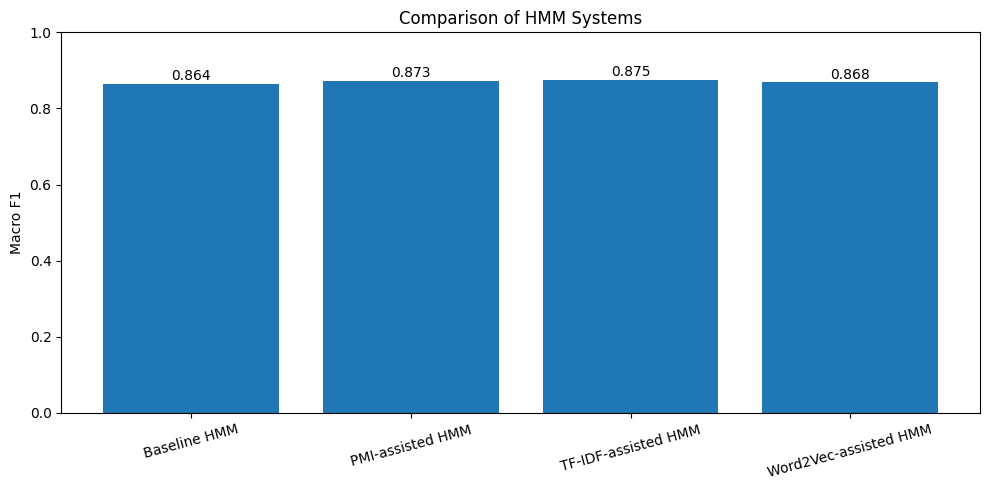

In [321]:
system_names = list(part3_test_metrics.keys())

macro_f1_values = [
    part3_test_metrics[name]["overall"]["macro_f1"]
    for name in system_names
]

plt.figure(figsize=(10, 5))

bars = plt.bar(system_names, macro_f1_values)

plt.ylim(0, 1)
plt.ylabel("Macro F1")
plt.title("Comparison of HMM Systems")
plt.xticks(rotation=15)

for bar, value in zip(bars, macro_f1_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

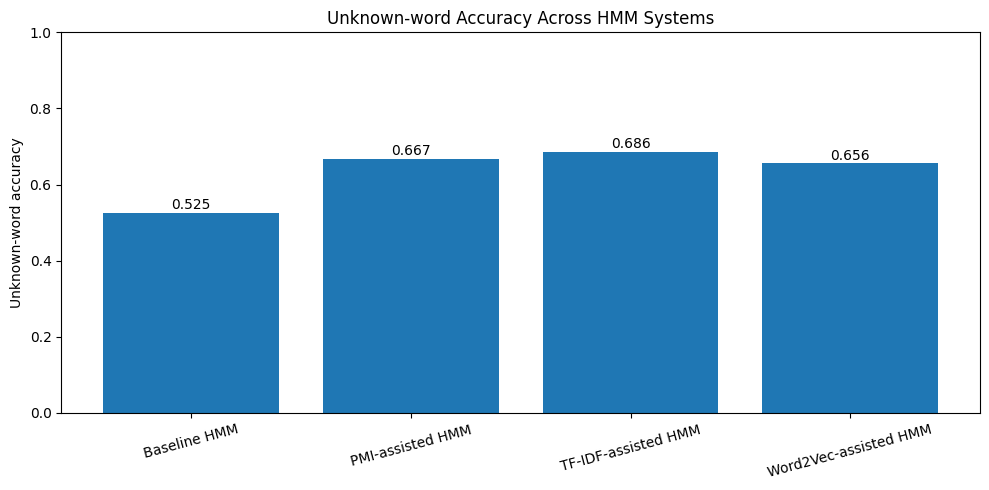

In [322]:
unknown_accuracy_values = [
    (
        part3_test_metrics[name]["unknown"]["accuracy"]
        if part3_test_metrics[name]["unknown"] is not None
        else 0
    )
    for name in system_names
]

plt.figure(figsize=(10, 5))

bars = plt.bar(system_names, unknown_accuracy_values)

plt.ylim(0, 1)
plt.ylabel("Unknown-word accuracy")
plt.title("Unknown-word Accuracy Across HMM Systems")
plt.xticks(rotation=15)

for bar, value in zip(bars, unknown_accuracy_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [323]:
# Unknown-word accuracy by true tag (most frequent tags among unknown tokens)
unknown_tag_counts = Counter(test_tags[si][pos] for si, pos in test_unknown_positions)

print(f"{'True tag':<10}{'n':>6}" + "".join(f"{name.replace(' HMM', ''):>24}" for name in system_names))

for tag, count in unknown_tag_counts.most_common(8):

    row = f"{tag:<10}{count:>6}"

    for system_name in system_names:

        correct = sum(
            part3_test_predictions[system_name][si][pos] == tag
            for si, pos in test_unknown_positions
            if test_tags[si][pos] == tag
        )

        row += f"{correct / count:>24.3f}"

    print(row)

True tag       n                Baseline            PMI-assisted         TF-IDF-assisted       Word2Vec-assisted
NNP         1473                   0.775                   0.768                   0.741                   0.780
NN           960                   0.491                   0.517                   0.562                   0.469
JJ           639                   0.640                   0.449                   0.615                   0.565
NNS          591                   0.166                   0.890                   0.876                   0.785
CD           427                   0.611                   0.754                   0.738                   0.782
VBN          220                   0.336                   0.805                   0.759                   0.782
VBG          189                   0.254                   0.910                   0.857                   0.868
VB           162                   0.667                   0.654                   0.778        

## 11. Error analysis

Unknown words that the assisted HMM fixed (**helped**) or broke (**hurt**) compared with the baseline, with the neighbours
that produced the evidence.

In [324]:
def tag_errors(representation_name, number_to_show=4):

    system_name = representation_name + "-assisted HMM"
    assisted_predictions = part3_test_predictions[system_name]

    helped = []
    hurt = []

    for si, pos in test_unknown_positions:

        true_tag = test_tags[si][pos]
        baseline_correct = baseline_predictions[si][pos] == true_tag
        assisted_correct = assisted_predictions[si][pos] == true_tag

        if not baseline_correct and assisted_correct:
            helped.append((si, pos))
        elif baseline_correct and not assisted_correct:
            hurt.append((si, pos))

    print("=" * 90)
    print(f"{representation_name}: helped {len(helped)}, hurt {len(hurt)} (net {len(helped) - len(hurt):+d})")

    for title, group in [("HELPED", helped), ("HURT", hurt)]:

        print(f"\n  --- {title} (first {number_to_show}) ---")

        for si, pos in group[:number_to_show]:

            sentence = test_sentences[si]
            start = max(0, pos - 3)
            end = min(len(sentence), pos + 4)
            result = part3_test_neighbors[representation_name][si].get(pos)

            print("  Word:", sentence[pos])
            print("  Context:", " ".join(sentence[start:end]))
            print(
                "  True:", test_tags[si][pos],
                "| Baseline:", baseline_predictions[si][pos],
                "| Assisted:", assisted_predictions[si][pos]
            )

            if result is not None:
                print("  Strategy:", result["method"])
                print(
                    "  Neighbours:",
                    ", ".join(f"{word}({similarity:.2f})" for word, similarity in result["neighbors"][:5])
                )

            print("  " + "-" * 40)


for representation_name in representation_names:
    tag_errors(representation_name)

PMI: helped 1113, hurt 395 (net +718)

  --- HELPED (first 4) ---
  Word: Tulsa
  Context: International Corp. 's Tulsa unit said it
  True: NNP | Baseline: JJ | Assisted: NNP
  Strategy: context+all
  Neighbours: the(0.14), and(0.14), The(0.13), .(0.13), ,(0.13)
  ----------------------------------------
  Word: extending
  Context: a tentative agreement extending its contract with
  True: VBG | Baseline: VBD | Assisted: VBG
  Strategy: context+suffix
  Neighbours: dropping(0.08), meeting(0.08), backing(0.07), offering(0.07), reaching(0.07)
  ----------------------------------------
  Word: jetliners
  Context: Boeing 's 747 jetliners .
  True: NNS | Baseline: CD | Assisted: NNS
  Strategy: context+suffix
  Neighbours: workers(0.16), Brussels(0.11), Aeronautics(0.10), hospitals(0.09), Netherlands(0.08)
  ----------------------------------------
  Word: shipsets
  Context: 200 additional so-called shipsets for the planes
  True: NNS | Baseline: NN | Assisted: NNS
  Strategy: context+su

In [325]:
def compare_unknown_errors(
    sentences,
    true_tag_sequences,
    predictions,
    vocabulary,
    number_to_show=15
):

    shown = 0

    for sentence_index, (sentence, true_tags) in enumerate(
        zip(sentences, true_tag_sequences)
    ):

        for position, (word, true_tag) in enumerate(
            zip(sentence, true_tags)
        ):

            if word in vocabulary:
                continue

            baseline_tag = predictions["Baseline HMM"][sentence_index][position]

            assisted_tags = {
                name: system_predictions[sentence_index][position]
                for name, system_predictions in predictions.items()
                if name != "Baseline HMM"
            }

            if (baseline_tag != true_tag or
                    any(tag != true_tag for tag in assisted_tags.values())):

                start = max(0, position - 2)
                end = min(len(sentence), position + 3)

                print("Word:", word)
                print("Context:", " ".join(sentence[start:end]))
                print("Actual tag:", true_tag)
                print("Baseline:", baseline_tag)

                for name, tag in assisted_tags.items():
                    print(name + ":", tag, "| Correct:", tag == true_tag)

                print("-" * 50)

                shown += 1

                if shown >= number_to_show:
                    return


compare_unknown_errors(
    test_sentences,
    test_tags,
    part3_test_predictions,
    final_hmm["vocabulary"]
)

Word: Tulsa
Context: Corp. 's Tulsa unit said
Actual tag: NNP
Baseline: JJ
PMI-assisted HMM: NNP | Correct: True
TF-IDF-assisted HMM: JJ | Correct: False
Word2Vec-assisted HMM: JJ | Correct: False
--------------------------------------------------
Word: extending
Context: tentative agreement extending its contract
Actual tag: VBG
Baseline: VBD
PMI-assisted HMM: VBG | Correct: True
TF-IDF-assisted HMM: VBG | Correct: True
Word2Vec-assisted HMM: VBG | Correct: True
--------------------------------------------------
Word: jetliners
Context: 's 747 jetliners .
Actual tag: NNS
Baseline: CD
PMI-assisted HMM: NNS | Correct: True
TF-IDF-assisted HMM: NNS | Correct: True
Word2Vec-assisted HMM: NNS | Correct: True
--------------------------------------------------
Word: shipsets
Context: additional so-called shipsets for the
Actual tag: NNS
Baseline: NN
PMI-assisted HMM: NNS | Correct: True
TF-IDF-assisted HMM: NNS | Correct: True
Word2Vec-assisted HMM: NNS | Correct: True
----------------------